In [8]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


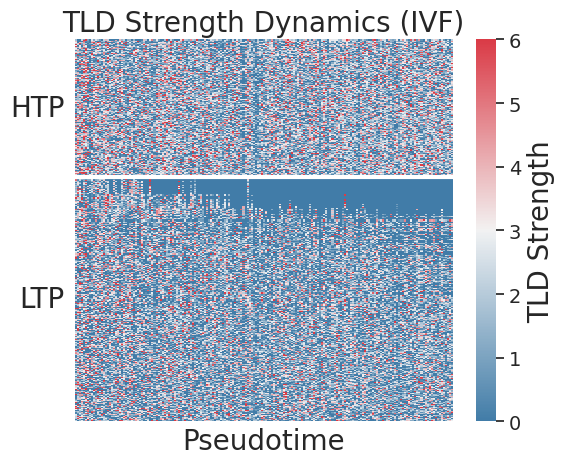

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from scipy.signal import savgol_filter

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =============================
# 全局绘图参数
# =============================
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20
})

# =============================
# 读取数据
# =============================
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)

time_df = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt",
    sep="\t", header=None, names=["sample", "time"]
)

sample_to_time = dict(zip(time_df["sample"], time_df["time"]))

# =============================
# 预处理
# =============================
# 去掉异常时间点
samples_to_remove = [s for s, t in sample_to_time.items() if 12.2 <= t <= 13.8]
tad_strength = tad_strength.drop(columns=samples_to_remove, errors='ignore')

# 保留有效信号（>=15个非0）
tad_strength = tad_strength[tad_strength.gt(0).sum(axis=1) >= 15]

# =============================
# KMeans 聚类（2类）
# =============================
kmeans = KMeans(n_clusters=2, random_state=99, n_init='auto')
tad_strength['cluster'] = kmeans.fit_predict(tad_strength)

# =============================
# 按平均强度重新定义 cluster（保证生物学意义）
# =============================
cluster_mean_strength = (
    tad_strength
    .drop(columns='cluster')
    .groupby(tad_strength['cluster'])
    .mean()
    .mean(axis=1)
)

# 高 → 低 排序
sorted_clusters = cluster_mean_strength.sort_values(ascending=False).index.tolist()

# 重新编号：高强度 = 0
cluster_remap = {old: new for new, old in enumerate(sorted_clusters)}
tad_strength['cluster'] = tad_strength['cluster'].map(cluster_remap)

# =============================
# cluster 顺序
# =============================
cluster_order = [0, 1]

# =============================
# 自动比例（推荐）
# =============================
total_display = 4538

cluster_counts = tad_strength['cluster'].value_counts(normalize=True)
cluster_ratio_map = {
    cid: cluster_counts.get(cid, 0)
    for cid in cluster_order
}

cluster_sizes = [int(total_display * cluster_ratio_map[c]) for c in cluster_order]
cluster_sizes[-1] = total_display - sum(cluster_sizes[:-1])

# =============================
# cluster 名称
# =============================
cluster_name_map = {
    0: "HTP",
    1: "LTP"
}

# =============================
# cluster 分组 & 排序
# =============================
clustered_data = []
cluster_boundaries = []
cluster_labels_pos = []

start = 0

for i, cid in enumerate(cluster_order):
    block = tad_strength[tad_strength['cluster'] == cid].drop(columns='cluster')

    # 行排序（增强结构）
    block = block.assign(row_mean=block.mean(axis=1)) \
                 .sort_values('row_mean') \
                 .drop(columns='row_mean')

    n = min(cluster_sizes[i], len(block))
    block = block.iloc[:n]

    clustered_data.append(block)

    start += n
    cluster_boundaries.append(start)
    cluster_labels_pos.append(start - n / 2)

# 合并
data_sorted = pd.concat(clustered_data)

# =============================
# 绘图（仅主热图）
# =============================
fig, ax_heat = plt.subplots(figsize=(6, 5))

cmap = sns.diverging_palette(240, 10, as_cmap=True)

sns.heatmap(
    data_sorted,
    cmap=cmap,
    vmin=0,
    vmax=6,
    yticklabels=False,
    xticklabels=False,
    cbar_kws={'label': 'TLD Strength'},
    ax=ax_heat
)



# 分割线
for y in cluster_boundaries[:-1]:
    ax_heat.axhline(y=y, color='white', linewidth=3)

# 标签
for pos, cid in zip(cluster_labels_pos, cluster_order):
    ax_heat.text(
        x=-5,
        y=pos,
        s=cluster_name_map[cid],
        va='center',
        ha='right',
        fontsize=20
    )

ax_heat.set_ylabel("")
ax_heat.set_title("TLD Strength Dynamics (IVF)", fontsize=20)
ax_heat.set_xlabel("Pseudotime", fontsize=20)   # 添加 x 轴标签

# 颜色条字体大小
cbar = ax_heat.collections[0].colorbar
cbar.ax.tick_params(labelsize=14)

# =============================
# 保存
# =============================
plt.tight_layout()
plt.savefig(
    "IVF_TLD_heatmap_2clusters.png",
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()

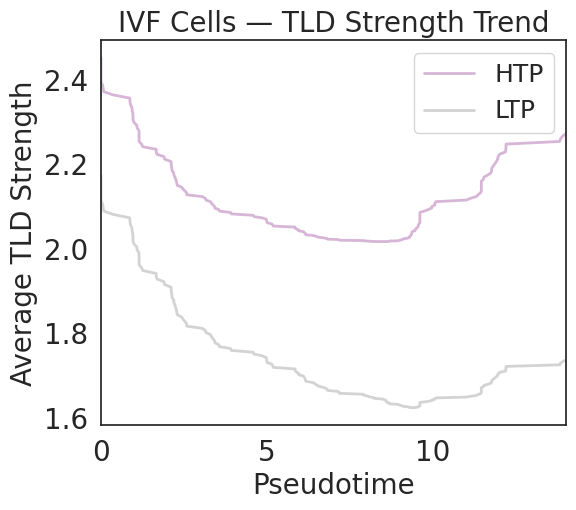

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.signal import savgol_filter

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ------------------------- 读取时间信息 -------------------------
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))

# ------------------------- 参数 -------------------------
optimal_k = 2
smooth_window = 200

fig, ax = plt.subplots(figsize=(6, 5))

# ---------- 颜色映射：按标签固定颜色 ----------
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}
# ----------------------------------------

# ------------------------- 绘制 Global Trend -------------------------
for i in range(optimal_k):
    cluster_data = tad_strength[tad_strength['cluster']==i].drop(columns='cluster')
    mean_values = cluster_data.mean(axis=0)

    time_vals = np.array([sample_to_time[s] for s in mean_values.index if s in sample_to_time])
    values = np.array([mean_values[s] for s in mean_values.index if s in sample_to_time])

    idx = np.argsort(time_vals)
    time_sorted, values_sorted = time_vals[idx], values[idx]

    window = min(smooth_window, len(values_sorted) if len(values_sorted)%2==1 else len(values_sorted)-1)
    smoothed = savgol_filter(values_sorted, window_length=window, polyorder=2) if window>=3 else values_sorted

    r, _ = pearsonr(time_sorted, smoothed)
    label = "HTP" if i == 0 else "LTP"
    ax.plot(time_sorted, smoothed, label=label,
            color=label_colors[label], linewidth=2)

ax.set_title('IVF Cells — TLD Strength Trend', fontsize=20)
ax.set_xlabel('Pseudotime', fontsize=20)
ax.set_ylabel('Average TLD Strength', fontsize=20)
ax.set_xlim(0, 14)
ax.legend(fontsize=18)

plt.savefig('IVF_TLDstrength_global.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


=== 4 Statistical Tests (Mann-Whitney U) ===
2C-H1: RRGP vs SRGP  p = 7.88e-01  ns
2C-H2: RRGP vs SRGP  p = 8.25e-01  ns
4C-H1: RRGP vs SRGP  p = 9.77e-01  ns
4C-H2: RRGP vs SRGP  p = 6.63e-01  ns


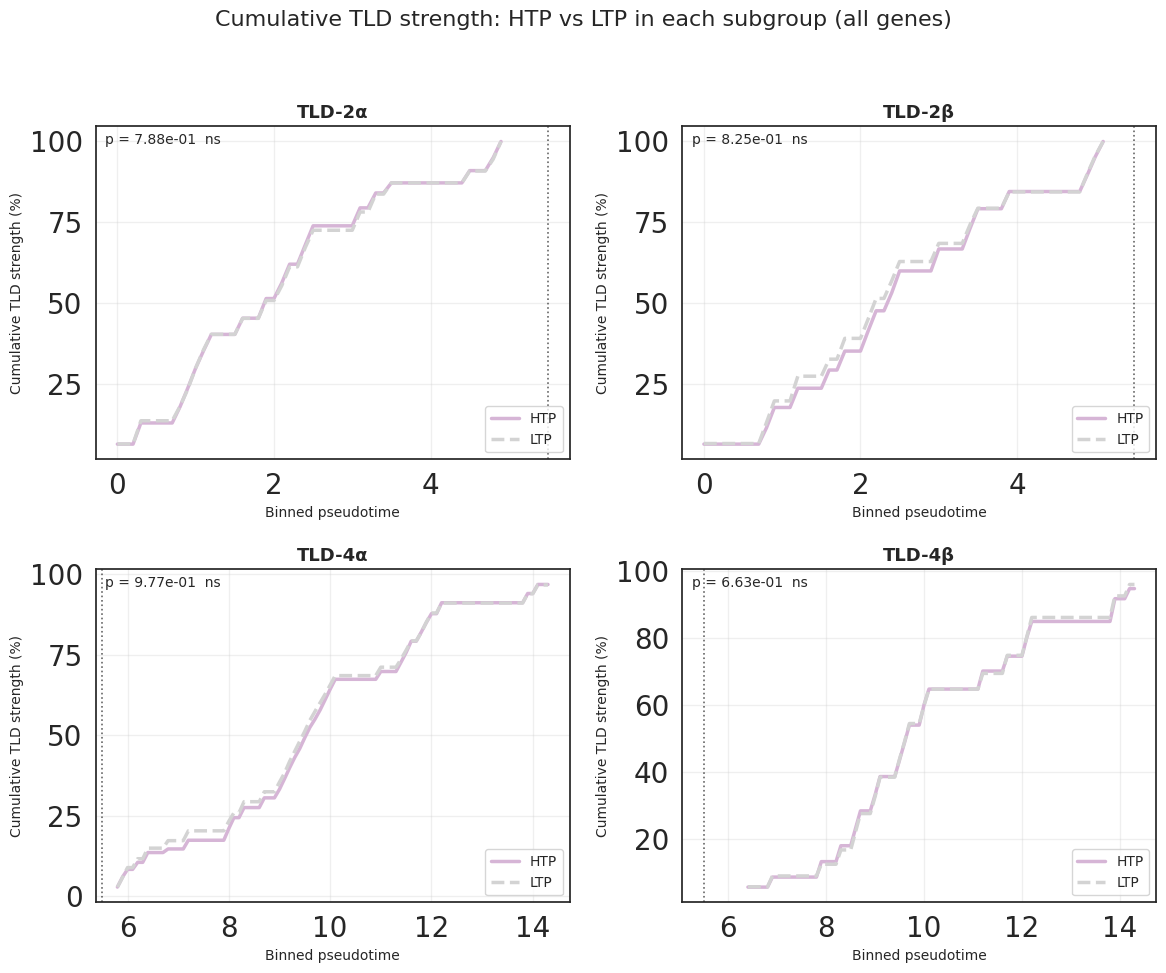

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

# =============================
# Matplotlib 设置
# =============================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =============================
# 参数设置
# =============================
BIN_SIZE = 0.1
min_time = 5.5

# ===========================================================================
# 辅助函数：读取 ID 列表
# ===========================================================================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        return [line.strip() for line in f if line.strip()]

# ===========================================================================
# 读取基因列表（TAD 区域相关基因）
# ===========================================================================
gene_list = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/expressed_genes.txt",
    header=None
)[0].tolist()
gene_set = set(gene_list)

# ===========================================================================
# 读取细胞亚群 ID
# ===========================================================================
subgroup_2C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# ===========================================================================
# 读取伪时间数据（假设已有 sample_to_time 字典）
# ===========================================================================
# time_df = pd.read_csv("IVF_scRNAseq_pseudotime_results_remove_gap.txt", sep="\t", header=0)
# sample_to_time = dict(zip(time_df["cell_id"], time_df["pseudotime"]))

# ===========================================================================
# 加载 tad_strength 数据（假设已存在）
# ===========================================================================
# tad_strength = pd.read_csv("your_tad_strength_file.csv", index_col=0)
# 必须包含 'cluster' 列，0=HTP, 1=LTP

# ===========================================================================
# 核心函数：构建分箱累积曲线
# ===========================================================================
def to_bin(t):
    return np.floor(t / BIN_SIZE) * BIN_SIZE

def build_binned_curve(times, values):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({"time": times, "value": values})
    df["bin"] = df["time"].apply(to_bin)
    bin_mean = df.groupby("bin")["value"].mean().reset_index()
    bin_mean = bin_mean.sort_values("bin")
    x = bin_mean["bin"].values
    v = bin_mean["value"].values
    cum = np.cumsum(v)
    return x, v, cum

def get_average_curve(cell_list, tad_df, sample_to_time, time_filter, filter_value):
    cell_means = []
    for cell in cell_list:
        if cell not in tad_df.columns:
            continue
        t = sample_to_time.get(cell)
        if t is None:
            continue
        if time_filter == '<=' and t > filter_value:
            continue
        if time_filter == '>=' and t < filter_value:
            continue
        mean_val = tad_df[cell].mean()
        cell_means.append((t, mean_val))
    if not cell_means:
        return None, None
    cell_means = np.array(cell_means)
    cell_means = cell_means[cell_means[:, 0].argsort()]
    times = cell_means[:, 0]
    values = cell_means[:, 1]
    x, _, cum = build_binned_curve(times, values)
    if len(cum) == 0:
        return None, None

    # ---- 归一化为百分比 ----
    total = cum[-1]
    if total != 0:
        cum = (cum / total) * 100
    else:
        cum = cum

    t_min, t_max = x[0], x[-1]
    time_grid = np.arange(t_min, t_max + BIN_SIZE/2, BIN_SIZE)
    f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
    cum_interp = f(time_grid)
    return time_grid, cum_interp

# ===========================================================================
# 显著性星号函数
# ===========================================================================
def sig_stars(p):
    if p < 0.0001:
        return '****'
    elif p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

# ===========================================================================
# 提取数据并准备曲线（RRGP 和 SRGP 分别处理）
# ===========================================================================
tad_rrgp = tad_strength[tad_strength['cluster'] == 0].drop(columns='cluster')
tad_srgp = tad_strength[tad_strength['cluster'] == 1].drop(columns='cluster')
tad_rrgp = tad_rrgp.loc[tad_rrgp.index.intersection(gene_set)]
tad_srgp = tad_srgp.loc[tad_srgp.index.intersection(gene_set)]

subgroups = {
    '2C-H1': subgroup_2C_H1,
    '2C-H2': subgroup_2C_H2,
    '4C-H1': subgroup_4C_H1,
    '4C-H2': subgroup_4C_H2
}

def get_curves_for_gene_set(tad_df, subgroups, sample_to_time, time_filter, filter_value):
    curves = {}
    for sg_name, sg_ids in subgroups.items():
        grid, cum = get_average_curve(sg_ids, tad_df, sample_to_time, time_filter, filter_value)
        if grid is not None:
            curves[sg_name] = (grid, cum)
    return curves

curves_rrgp_2c = get_curves_for_gene_set(tad_rrgp, subgroups, sample_to_time, '<=', min_time)
curves_rrgp_4c = get_curves_for_gene_set(tad_rrgp, subgroups, sample_to_time, '>=', min_time)
curves_srgp_2c = get_curves_for_gene_set(tad_srgp, subgroups, sample_to_time, '<=', min_time)
curves_srgp_4c = get_curves_for_gene_set(tad_srgp, subgroups, sample_to_time, '>=', min_time)

# ===========================================================================
# 只计算 4 个比较：同一亚群内 RRGP vs SRGP
# ===========================================================================
comparison_list = [
    ('2C-H1', 'RRGP', 'SRGP'),
    ('2C-H2', 'RRGP', 'SRGP'),
    ('4C-H1', 'RRGP', 'SRGP'),
    ('4C-H2', 'RRGP', 'SRGP')
]

p_values = {}

for sg, g1, g2 in comparison_list:
    if '2C' in sg:
        curves_r = curves_rrgp_2c
        curves_s = curves_srgp_2c
    else:
        curves_r = curves_rrgp_4c
        curves_s = curves_srgp_4c

    if sg in curves_r and sg in curves_s:
        grid_r, cum_r = curves_r[sg]
        grid_s, cum_s = curves_s[sg]
        common = np.sort(np.unique(np.concatenate([grid_r, grid_s])))
        f_r = interp1d(grid_r, cum_r, kind='linear', fill_value=(cum_r[0], cum_r[-1]), bounds_error=False)
        f_s = interp1d(grid_s, cum_s, kind='linear', fill_value=(cum_s[0], cum_s[-1]), bounds_error=False)
        p = mannwhitneyu(f_r(common), f_s(common), alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[(sg, g1, g2)] = p

print("\n=== 4 Statistical Tests (Mann-Whitney U) ===")
for (sg, g1, g2), p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: {g1} vs {g2}  p = {p:.2e}  {sig_stars(p)}")
    else:
        print(f"{sg}: NA")

# ===========================================================================
# 绘图：4个子图，每个亚群一个
# ===========================================================================
# HTP / LTP 配色
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-H1': 'TLD-2α',
    '2C-H2': 'TLD-2β',
    '4C-H1': 'TLD-4α',
    '4C-H2': 'TLD-4β',
}

# 子图顺序
subgroup_order = ['2C-H1', '2C-H2', '4C-H1', '4C-H2']

# 创建 2x2 子图
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]

    # 获取该亚群对应的 HTP 和 LTP 曲线
    if '2C' in sg:
        curves_htp = curves_rrgp_2c
        curves_ltp = curves_srgp_2c
    else:
        curves_htp = curves_rrgp_4c
        curves_ltp = curves_srgp_4c

    # 绘制 HTP（实线）
    if sg in curves_htp:
        grid_htp, cum_htp = curves_htp[sg]
        ax.plot(grid_htp, cum_htp, color=label_colors['HTP'],
                linestyle='-', lw=2.5, label='HTP')

    # 绘制 LTP（虚线）
    if sg in curves_ltp:
        grid_ltp, cum_ltp = curves_ltp[sg]
        ax.plot(grid_ltp, cum_ltp, color=label_colors['LTP'],
                linestyle='--', lw=2.5, label='LTP')

    # 垂直虚线（分割时间点）
    ax.axvline(min_time, color='black', linestyle=':', lw=1.2, alpha=0.6)

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')

    # 轴标签
    ax.set_xlabel("Binned pseudotime", fontsize=10)
    ax.set_ylabel("Cumulative TLD strength (%)", fontsize=10)

    # 图例
    ax.legend(loc='lower right', fontsize=10, framealpha=0.8)

    # 显示 p 值
    key = (sg, 'RRGP', 'SRGP')
    p = p_values.get(key, np.nan)
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {sig_stars(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left',
            fontsize=10)

    ax.grid(alpha=0.3)

# 整体大标题
fig.suptitle("Cumulative TLD strength: HTP vs LTP in each subgroup (all genes)",
             fontsize=16, y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Cumulative_TLD_strength_HTP_LTP_subgroups.svg",
            dpi=300, bbox_inches='tight')
plt.show()


=== Statistical Tests (Mann-Whitney U) by period ===
2C: HTP vs LTP  p = 1.32e-05  ****
4C: HTP vs LTP  p = 2.25e-18  ****


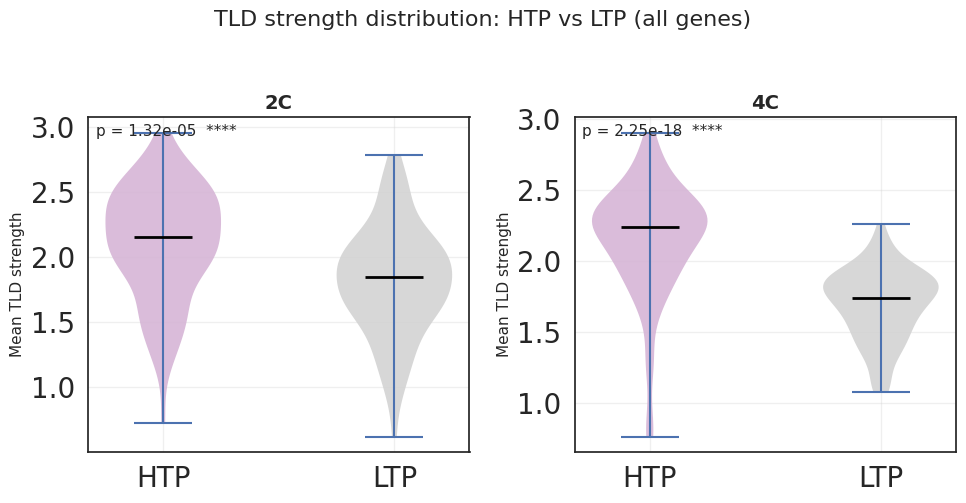

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# =============================
# Matplotlib 设置
# =============================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =============================
# 辅助函数
# =============================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        return [line.strip() for line in f if line.strip()]

def sig_stars(p):
    if p < 0.0001:
        return '****'
    elif p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

# ===========================================================================
# 读取数据
# ===========================================================================
# 基因列表
gene_list = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/expressed_genes.txt",
    header=None
)[0].tolist()
gene_set = set(gene_list)

# 细胞亚群ID（分别读取四个文件）
subgroup_2C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# ===========================================================================
# 加载 TAD strength 数据（需包含 'cluster' 列：0=RRGP (HTP), 1=SRGP (LTP)）
# ===========================================================================
# tad_strength = pd.read_csv("your_tad_strength_file.csv", index_col=0)
# 此处假设变量已存在，实际使用时请取消注释并替换

# 分离 HTP (原RRGP) 和 LTP (原SRGP)
tad_htp = tad_strength[tad_strength['cluster'] == 0].drop(columns='cluster')
tad_ltp = tad_strength[tad_strength['cluster'] == 1].drop(columns='cluster')

# 只保留基因列表中的基因
tad_htp = tad_htp.loc[tad_htp.index.intersection(gene_set)]
tad_ltp = tad_ltp.loc[tad_ltp.index.intersection(gene_set)]

# ===========================================================================
# 合并细胞亚群为时期（2C 和 4C）
# ===========================================================================
cells_2C = subgroup_2C_H1 + subgroup_2C_H2
cells_4C = subgroup_4C_H1 + subgroup_4C_H2

periods = {
    '2C': cells_2C,
    '4C': cells_4C
}

# ===========================================================================
# 提取每个细胞的平均 TAD strength（按时期和类型）
# ===========================================================================
def get_cell_means(cell_list, tad_df):
    """返回给定细胞列表中每个细胞的平均TAD strength（若细胞不在tad_df中则跳过）"""
    values = []
    for cell in cell_list:
        if cell in tad_df.columns:
            values.append(tad_df[cell].mean())
    return values

data = {}
p_values = {}
period_order = ['2C', '4C']

for period in period_order:
    cells = periods[period]
    htp_vals = get_cell_means(cells, tad_htp)
    ltp_vals = get_cell_means(cells, tad_ltp)
    data[period] = {'HTP': htp_vals, 'LTP': ltp_vals}

    # 统计检验
    if len(htp_vals) > 0 and len(ltp_vals) > 0:
        p = mannwhitneyu(htp_vals, ltp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[period] = p

# 打印检验结果
print("\n=== Statistical Tests (Mann-Whitney U) by period ===")
for period, p in p_values.items():
    if not np.isnan(p):
        print(f"{period}: HTP vs LTP  p = {p:.2e}  {sig_stars(p)}")
    else:
        print(f"{period}: NA")

# ===========================================================================
# 绘制小提琴图：一行两列，分别显示 2C 和 4C
# ===========================================================================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))  # 一行两列

for idx, period in enumerate(period_order):
    ax = axes[idx]
    vals = data[period]

    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    # 中位线样式
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])
    ax.set_title(period, fontsize=14, fontweight='bold')
    ax.set_ylabel("Mean TLD strength", fontsize=11)

    # p值标注
    p = p_values[period]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {sig_stars(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=11)

    ax.grid(alpha=0.3)

plt.suptitle("TLD strength distribution: HTP vs LTP (all genes)", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("Violin_TLD_strength_HTP_LTP_by_period.svg", dpi=300, bbox_inches='tight')
plt.show()


=== Statistical Tests (Mann-Whitney U) ===
2C-H1: HTP vs LTP  p = 1.35e-03  **
2C-H2: HTP vs LTP  p = 2.01e-03  **
4C-H1: HTP vs LTP  p = 7.10e-14  ****
4C-H2: HTP vs LTP  p = 7.65e-06  ****


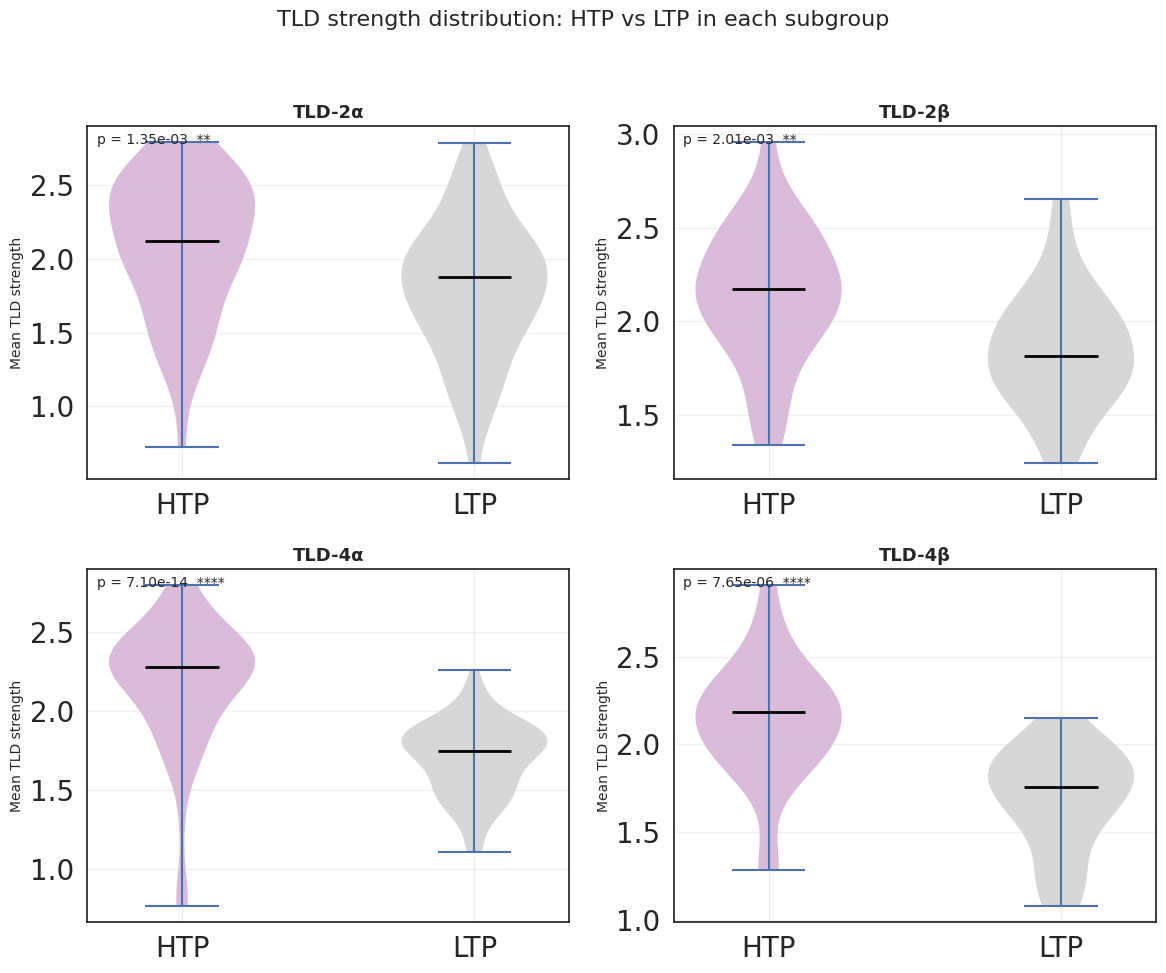

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# =============================
# Matplotlib 设置
# =============================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =============================
# 辅助函数
# =============================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        return [line.strip() for line in f if line.strip()]

def sig_stars(p):
    if p < 0.0001:
        return '****'
    elif p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

# ===========================================================================
# 读取数据
# ===========================================================================
# 基因列表
gene_list = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/expressed_genes.txt",
    header=None
)[0].tolist()
gene_set = set(gene_list)

# 细胞亚群ID
subgroup_2C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# ===========================================================================
# 加载 TAD strength 数据（需包含 'cluster' 列：0=RRGP, 1=SRGP）
# ===========================================================================
# tad_strength = pd.read_csv("your_tad_strength_file.csv", index_col=0)
# 这里用占位数据，实际请取消注释并替换为真实文件

# 假设已有 tad_strength DataFrame
# tad_strength = ...

# 分离 RRGP 和 SRGP
tad_rrgp = tad_strength[tad_strength['cluster'] == 0].drop(columns='cluster')
tad_srgp = tad_strength[tad_strength['cluster'] == 1].drop(columns='cluster')

# 只保留基因列表中的基因
tad_rrgp = tad_rrgp.loc[tad_rrgp.index.intersection(gene_set)]
tad_srgp = tad_srgp.loc[tad_srgp.index.intersection(gene_set)]

# 亚群字典
subgroups = {
    '2C-H1': subgroup_2C_H1,
    '2C-H2': subgroup_2C_H2,
    '4C-H1': subgroup_4C_H1,
    '4C-H2': subgroup_4C_H2
}

# ===========================================================================
# 提取每个细胞的平均 TAD strength
# ===========================================================================
def get_cell_means(cell_list, tad_df):
    """返回给定细胞列表中每个细胞的平均TAD strength"""
    values = []
    for cell in cell_list:
        if cell in tad_df.columns:
            values.append(tad_df[cell].mean())
    return values

data = {}
p_values = {}
subgroup_order = ['2C-H1', '2C-H2', '4C-H1', '4C-H2']

for sg in subgroup_order:
    cells = subgroups[sg]
    rrgp_vals = get_cell_means(cells, tad_rrgp)
    srgp_vals = get_cell_means(cells, tad_srgp)
    data[sg] = {'HTP': rrgp_vals, 'LTP': srgp_vals}

    # 统计检验
    if len(rrgp_vals) > 0 and len(srgp_vals) > 0:
        p = mannwhitneyu(rrgp_vals, srgp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[sg] = p

# 打印检验结果
print("\n=== Statistical Tests (Mann-Whitney U) ===")
for sg, p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: HTP vs LTP  p = {p:.2e}  {sig_stars(p)}")
    else:
        print(f"{sg}: NA")

# ===========================================================================
# 绘制小提琴图
# ===========================================================================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-H1': 'TLD-2α',
    '2C-H2': 'TLD-2β',
    '4C-H1': 'TLD-4α',
    '4C-H2': 'TLD-4β',
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]
    vals = data[sg]

    # 绘制小提琴图（两个组：HTP和LTP）
    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    # 中位线样式
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    # 坐标轴
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')
    ax.set_ylabel("Mean TLD strength", fontsize=10)

    # p值标注
    p = p_values[sg]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {sig_stars(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=10)

    ax.grid(alpha=0.3)

plt.suptitle("TLD strength distribution: HTP vs LTP in each subgroup",
             fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Violin_TLD_strength_HTP_LTP_subgroups.svg", dpi=300, bbox_inches='tight')
plt.show()


=== Statistical Tests (Mann-Whitney U) ===
2C-H1: HTP vs LTP  p = 2.08e-03  **
2C-H2: HTP vs LTP  p = 6.36e-03  **
4C-H1: HTP vs LTP  p = 2.55e-12  ****
4C-H2: HTP vs LTP  p = 6.88e-05  ****


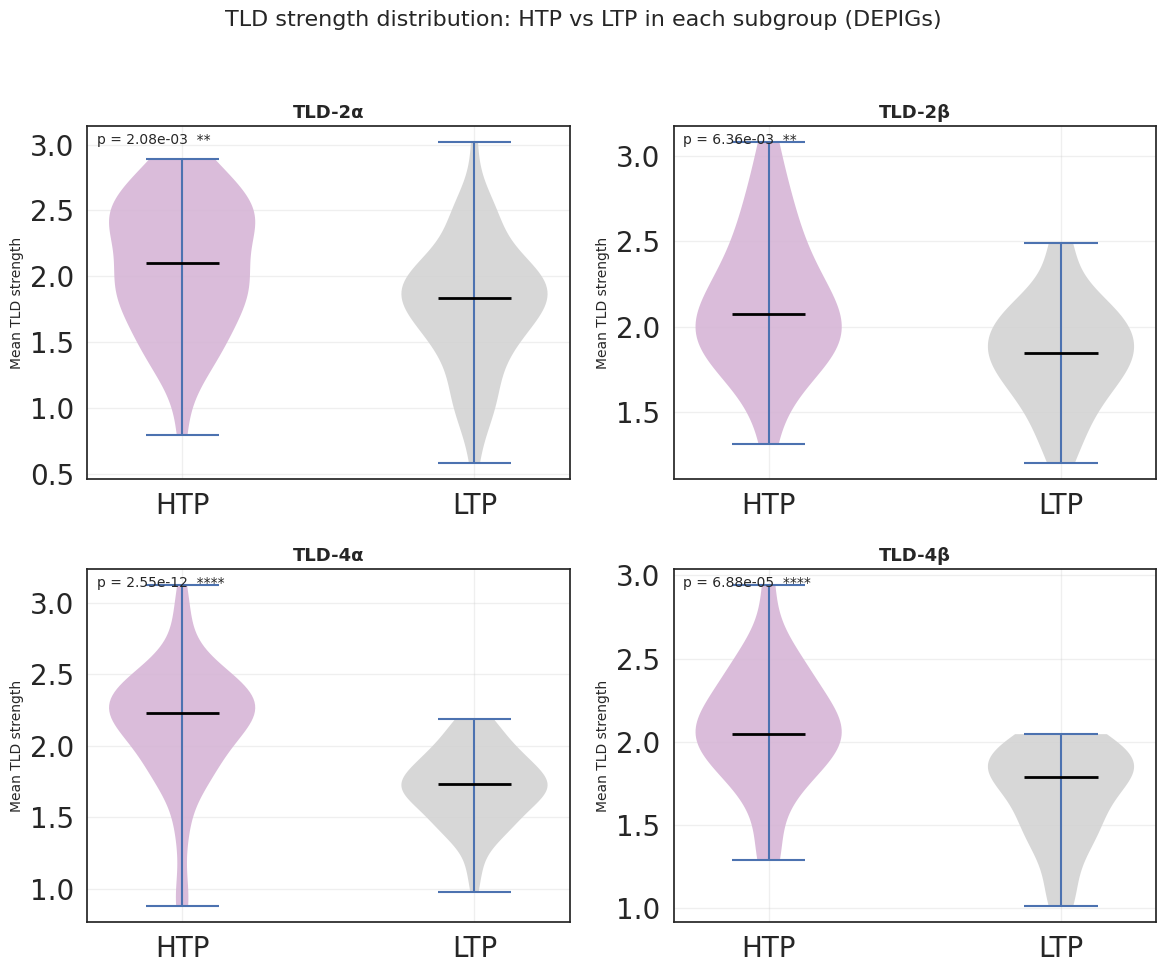

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# =============================
# Matplotlib 设置
# =============================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =============================
# 辅助函数
# =============================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        return [line.strip() for line in f if line.strip()]

def sig_stars(p):
    if p < 0.0001:
        return '****'
    elif p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

# ===========================================================================
# 读取数据
# ===========================================================================
# 基因列表
gene_list = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/IVF_morula_boundaries_80k_2C_4C_deboundary2gene_id.txt",
    header=None
)[0].tolist()
gene_set = set(gene_list)

# 细胞亚群ID
subgroup_2C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# ===========================================================================
# 加载 TAD strength 数据（需包含 'cluster' 列：0=RRGP, 1=SRGP）
# ===========================================================================
# tad_strength = pd.read_csv("your_tad_strength_file.csv", index_col=0)
# 这里用占位数据，实际请取消注释并替换为真实文件

# 假设已有 tad_strength DataFrame
# tad_strength = ...

# 分离 RRGP 和 SRGP
tad_rrgp = tad_strength[tad_strength['cluster'] == 0].drop(columns='cluster')
tad_srgp = tad_strength[tad_strength['cluster'] == 1].drop(columns='cluster')

# 只保留基因列表中的基因
tad_rrgp = tad_rrgp.loc[tad_rrgp.index.intersection(gene_set)]
tad_srgp = tad_srgp.loc[tad_srgp.index.intersection(gene_set)]

# 亚群字典
subgroups = {
    '2C-H1': subgroup_2C_H1,
    '2C-H2': subgroup_2C_H2,
    '4C-H1': subgroup_4C_H1,
    '4C-H2': subgroup_4C_H2
}

# ===========================================================================
# 提取每个细胞的平均 TAD strength
# ===========================================================================
def get_cell_means(cell_list, tad_df):
    """返回给定细胞列表中每个细胞的平均TAD strength"""
    values = []
    for cell in cell_list:
        if cell in tad_df.columns:
            values.append(tad_df[cell].mean())
    return values

data = {}
p_values = {}
subgroup_order = ['2C-H1', '2C-H2', '4C-H1', '4C-H2']

for sg in subgroup_order:
    cells = subgroups[sg]
    rrgp_vals = get_cell_means(cells, tad_rrgp)
    srgp_vals = get_cell_means(cells, tad_srgp)
    data[sg] = {'HTP': rrgp_vals, 'LTP': srgp_vals}

    # 统计检验
    if len(rrgp_vals) > 0 and len(srgp_vals) > 0:
        p = mannwhitneyu(rrgp_vals, srgp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[sg] = p

# 打印检验结果
print("\n=== Statistical Tests (Mann-Whitney U) ===")
for sg, p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: HTP vs LTP  p = {p:.2e}  {sig_stars(p)}")
    else:
        print(f"{sg}: NA")

# ===========================================================================
# 绘制小提琴图
# ===========================================================================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-H1': 'TLD-2α',
    '2C-H2': 'TLD-2β',
    '4C-H1': 'TLD-4α',
    '4C-H2': 'TLD-4β',
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]
    vals = data[sg]

    # 绘制小提琴图（两个组：HTP和LTP）
    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    # 中位线样式
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    # 坐标轴
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')
    ax.set_ylabel("Mean TLD strength", fontsize=10)

    # p值标注
    p = p_values[sg]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {sig_stars(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=10)

    ax.grid(alpha=0.3)

plt.suptitle("TLD strength distribution: HTP vs LTP in each subgroup (DEPIGs)",
             fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Violin_TLD_strength_HTP_LTP_subgroups_DEPIGs.svg",
            dpi=300, bbox_inches='tight')
plt.show()

Loaded APA data: 610 rows

=== 4 Statistical Tests (Mann-Whitney U) ===
2C-H1: HTP vs LTP  p = 8.58e-01  ns
2C-H2: HTP vs LTP  p = 4.46e-01  ns
4C-H1: HTP vs LTP  p = 9.04e-01  ns
4C-H2: HTP vs LTP  p = 6.58e-01  ns


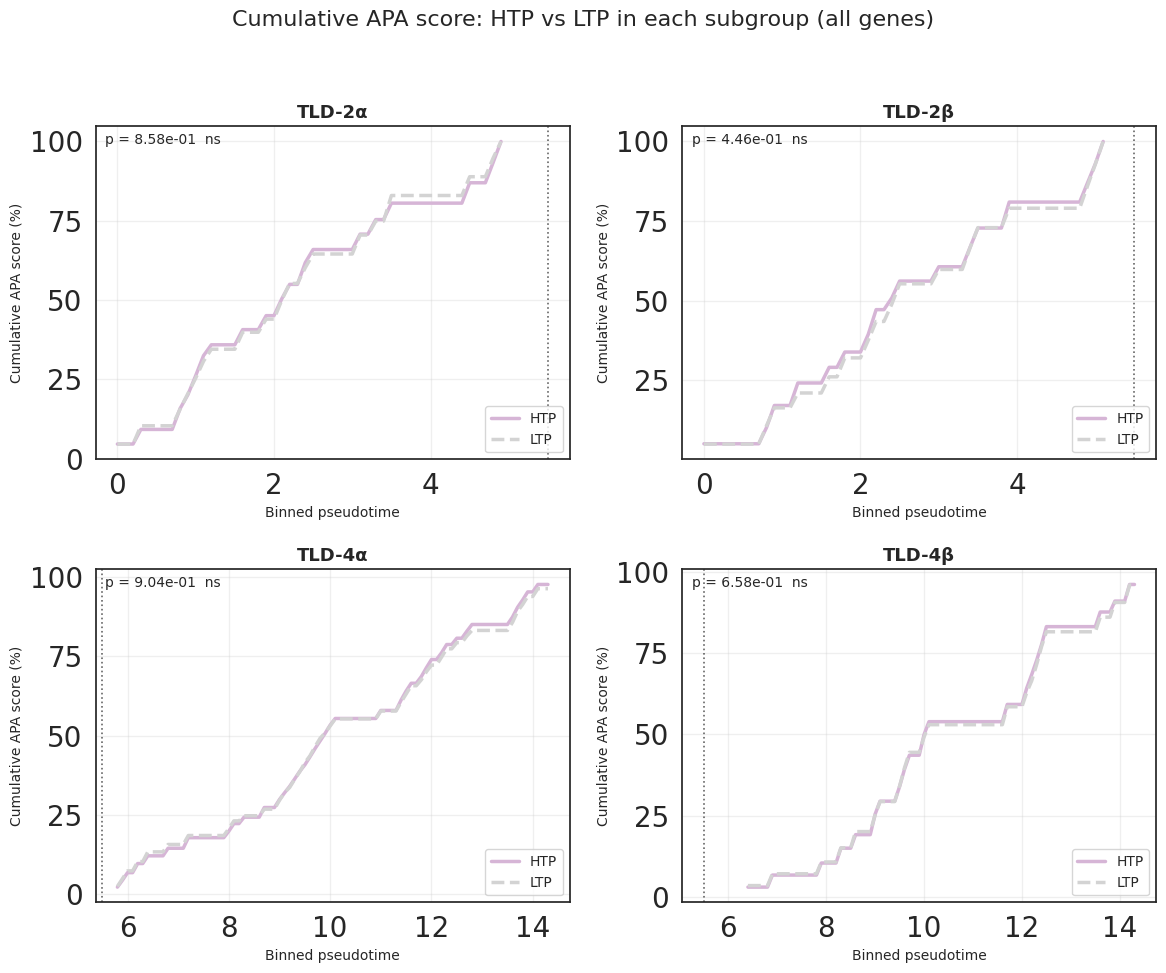

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from scipy.interpolate import interp1d

# =========================
# PARAMS
# =========================
BIN_SIZE = 0.1
min_time = 5.5

# =========================
# 辅助函数：多级显著性标注
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# =========================
# 时间分箱
# =========================
def to_bin(t):
    return np.floor(t / BIN_SIZE) * BIN_SIZE

# =========================
# 构建累积曲线（绝对值累积）
# =========================
def build_binned_curve(df):
    df = df.copy()
    df["bin"] = df["time"].apply(to_bin)
    bin_mean = df.groupby("bin")["value"].mean().reset_index()
    bin_mean = bin_mean.sort_values("bin")
    x = bin_mean["bin"].values
    v = bin_mean["value"].values
    if len(v) == 0:
        return np.array([]), np.array([]), np.array([])
    cum = np.cumsum(v)
    return x, v, cum

# =========================
# 获取某个基因集（HTP/LTP）在各亚群中的累积曲线（插值后）
# =========================
def get_curves_for_gene_set(z_df, gene_set_type, subgroups, sample_to_time, time_filter, filter_value):
    data = z_df[z_df["type"] == gene_set_type].copy()
    data["time"] = data["cell"].map(sample_to_time)
    data = data.dropna(subset=["time"])

    curves = {}
    for sg_name, cell_ids in subgroups.items():
        sub = data[data["cell"].isin(cell_ids)]
        if time_filter == '<=':
            sub = sub[sub["time"] <= filter_value]
        else:  # '>='
            sub = sub[sub["time"] >= filter_value]
        if sub.empty:
            continue
        cell_means = sub.groupby("cell")["z_score"].mean().reset_index()
        cell_means = cell_means.merge(sub[["cell", "time"]].drop_duplicates(), on="cell")
        df = cell_means[["time", "z_score"]].rename(columns={"z_score": "value"})
        x, _, cum = build_binned_curve(df)
        if len(cum) == 0:
            continue

        # ---- 归一化为百分比 ----
        total = cum[-1]
        if total != 0:
            cum = (cum / total) * 100
        # 若 total == 0，则 cum 保持全零

        t_min, t_max = x[0], x[-1]
        grid = np.arange(t_min, t_max + BIN_SIZE/2, BIN_SIZE)
        f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
        cum_interp = f(grid)
        curves[sg_name] = (grid, cum_interp)
    return curves

# =========================
# 读取数据（您指定的文件）
# =========================
apa_df = pd.read_csv(
    "/home/lihaoxing/loop_apa_0.925/single_cell/ivf_pa_2cluster/matrix/APA_zscore_summary_ivf.txt",
    sep="\t"
)
apa_df = apa_df.rename(columns={'file': 'cell'})  # 列名已经是 type, z_score
# 确保 type 列为 c0/c1，z_score 为数值
apa_df['z_score'] = pd.to_numeric(apa_df['z_score'])
print(f"Loaded APA data: {apa_df.shape[0]} rows")

# =========================
# 定义亚群字典（请确保这些变量已定义）
# =========================
subgroups = {
    '2C-H1': subgroup_2C_H1,
    '2C-H2': subgroup_2C_H2,
    '4C-H1': subgroup_4C_H1,
    '4C-H2': subgroup_4C_H2
}

# =========================
# 获取 HTP (c0) 和 LTP (c1) 的曲线（2C 和 4C 分开）
# =========================
curves_htp_2c = get_curves_for_gene_set(apa_df, 'c0', subgroups, sample_to_time, '<=', min_time)
curves_htp_4c = get_curves_for_gene_set(apa_df, 'c0', subgroups, sample_to_time, '>=', min_time)
curves_ltp_2c = get_curves_for_gene_set(apa_df, 'c1', subgroups, sample_to_time, '<=', min_time)
curves_ltp_4c = get_curves_for_gene_set(apa_df, 'c1', subgroups, sample_to_time, '>=', min_time)

# =========================
# 只计算 4 个比较：同一亚群内 HTP vs LTP
# =========================
comparison_list = [
    ('2C-H1', 'HTP', 'LTP'),
    ('2C-H2', 'HTP', 'LTP'),
    ('4C-H1', 'HTP', 'LTP'),
    ('4C-H2', 'HTP', 'LTP')
]

p_values = {}

for sg, g1, g2 in comparison_list:
    if '2C' in sg:
        curves_h = curves_htp_2c
        curves_l = curves_ltp_2c
    else:
        curves_h = curves_htp_4c
        curves_l = curves_ltp_4c

    if sg in curves_h and sg in curves_l:
        grid_h, cum_h = curves_h[sg]
        grid_l, cum_l = curves_l[sg]
        common = np.sort(np.unique(np.concatenate([grid_h, grid_l])))
        f_h = interp1d(grid_h, cum_h, kind='previous', fill_value=(cum_h[0], cum_h[-1]), bounds_error=False)
        f_l = interp1d(grid_l, cum_l, kind='previous', fill_value=(cum_l[0], cum_l[-1]), bounds_error=False)
        p = mannwhitneyu(f_h(common), f_l(common), alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[(sg, g1, g2)] = p

print("\n=== 4 Statistical Tests (Mann-Whitney U) ===")
for (sg, g1, g2), p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: {g1} vs {g2}  p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{sg}: NA")

# =========================
# 绘图：4个子图，每个亚群一个
# =========================
# HTP / LTP 配色
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-H1': 'TLD-2α',
    '2C-H2': 'TLD-2β',
    '4C-H1': 'TLD-4α',
    '4C-H2': 'TLD-4β',
}

subgroup_order = ['2C-H1', '2C-H2', '4C-H1', '4C-H2']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]

    if '2C' in sg:
        curves_h = curves_htp_2c
        curves_l = curves_ltp_2c
    else:
        curves_h = curves_htp_4c
        curves_l = curves_ltp_4c

    # HTP（实线）
    if sg in curves_h:
        grid_h, cum_h = curves_h[sg]
        ax.plot(grid_h, cum_h, color=label_colors['HTP'],
                linestyle='-', lw=2.5, label='HTP')

    # LTP（虚线）
    if sg in curves_l:
        grid_l, cum_l = curves_l[sg]
        ax.plot(grid_l, cum_l, color=label_colors['LTP'],
                linestyle='--', lw=2.5, label='LTP')

    ax.axvline(min_time, color='black', linestyle=':', lw=1.2, alpha=0.6)

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')

    ax.set_xlabel("Binned pseudotime", fontsize=10)
    ax.set_ylabel("Cumulative APA score (%)", fontsize=10)
    ax.legend(loc='lower right', fontsize=10, framealpha=0.8)

    key = (sg, 'HTP', 'LTP')
    p = p_values.get(key, np.nan)
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {get_p_annotation(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left',
            fontsize=10)

    ax.grid(alpha=0.3)

fig.suptitle("Cumulative APA score: HTP vs LTP in each subgroup (all genes)",
             fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Cumulative_APA_HTP_LTP_subgroups_percentage.svg",
            dpi=300, bbox_inches='tight')
plt.show()

Loaded APA data: 610 rows

=== Statistical Tests (Mann-Whitney U) by period ===
2C: HTP vs LTP  p = 2.84e-10  ****
4C: HTP vs LTP  p = 1.69e-03  **


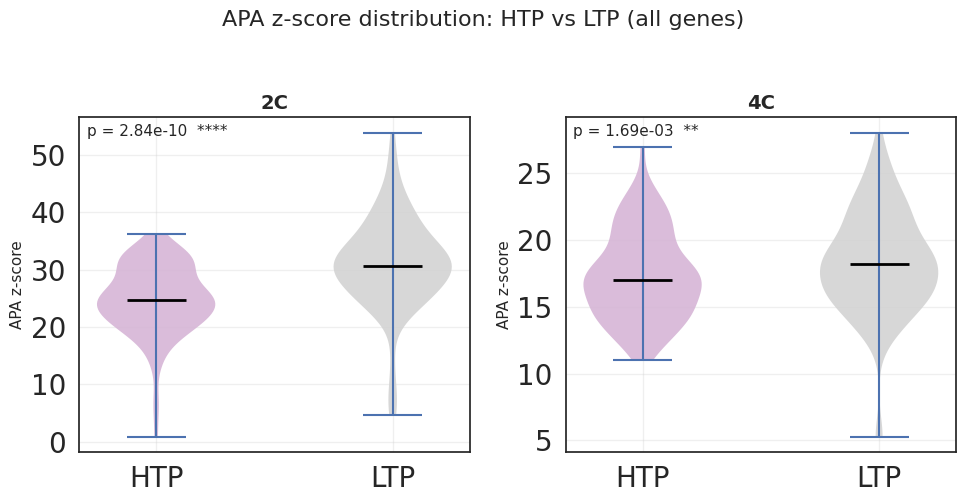

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# =========================
# 辅助函数：多级显著性标注
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# =========================
# 读取数据
# =========================
apa_df = pd.read_csv(
    "/home/lihaoxing/loop_apa_0.925/single_cell/ivf_pa_2cluster/matrix/APA_zscore_summary_ivf.txt",
    sep="\t"
)
apa_df = apa_df.rename(columns={'file': 'cell'})
apa_df['z_score'] = pd.to_numeric(apa_df['z_score'])
print(f"Loaded APA data: {apa_df.shape[0]} rows")

# =========================
# 定义细胞亚群（假设这些变量已存在）
# =========================
# 细胞亚群ID
subgroup_2C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_H1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_H2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")


# 合并细胞为时期
cells_2C = subgroup_2C_H1 + subgroup_2C_H2
cells_4C = subgroup_4C_H1 + subgroup_4C_H2

periods = {
    '2C': cells_2C,
    '4C': cells_4C
}

# =========================
# 提取每个时期 HTP (c0) 和 LTP (c1) 的 z_score
# =========================
data = {}
p_values = {}
period_order = ['2C', '4C']

for period in period_order:
    cells = set(periods[period])
    sub_df = apa_df[apa_df['cell'].isin(cells)]
    htp_vals = sub_df[sub_df['type'] == 'c0']['z_score'].values
    ltp_vals = sub_df[sub_df['type'] == 'c1']['z_score'].values
    data[period] = {'HTP': htp_vals, 'LTP': ltp_vals}

    if len(htp_vals) > 0 and len(ltp_vals) > 0:
        p = mannwhitneyu(htp_vals, ltp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[period] = p

# 打印结果
print("\n=== Statistical Tests (Mann-Whitney U) by period ===")
for period, p in p_values.items():
    if not np.isnan(p):
        print(f"{period}: HTP vs LTP  p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{period}: NA")

# =========================
# 绘制小提琴图（一行两列）
# =========================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for idx, period in enumerate(period_order):
    ax = axes[idx]
    vals = data[period]

    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])
    ax.set_title(period, fontsize=14, fontweight='bold')
    ax.set_ylabel("APA z-score", fontsize=11)

    p = p_values[period]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {get_p_annotation(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=11)

    ax.grid(alpha=0.3)

plt.suptitle("APA z-score distribution: HTP vs LTP (all genes)", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("Violin_APA_HTP_LTP_by_period.svg", dpi=300, bbox_inches='tight')
plt.show()

Loaded APA data: 610 rows

=== Statistical Tests (Mann-Whitney U) ===
2C-H1: HTP vs LTP  p = 1.65e-08  ****
2C-H2: HTP vs LTP  p = 1.64e-03  **
4C-H1: HTP vs LTP  p = 1.86e-02  *
4C-H2: HTP vs LTP  p = 3.69e-02  *


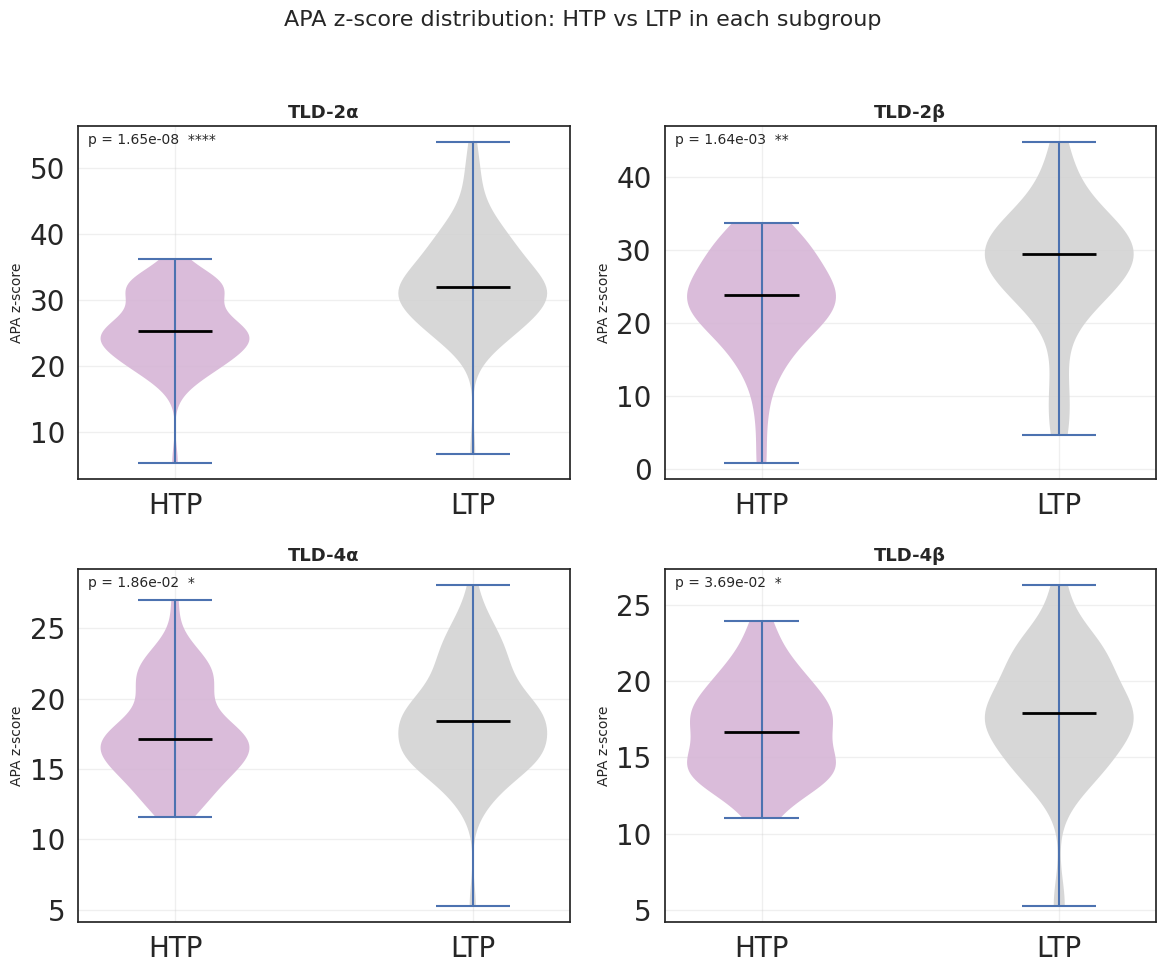

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# =========================
# 辅助函数：多级显著性标注
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# =========================
# 读取数据
# =========================
apa_df = pd.read_csv(
    "/home/lihaoxing/loop_apa_0.925/single_cell/ivf_pa_2cluster/matrix/APA_zscore_summary_ivf.txt",
    sep="\t"
)
apa_df = apa_df.rename(columns={'file': 'cell'})
apa_df['z_score'] = pd.to_numeric(apa_df['z_score'])
print(f"Loaded APA data: {apa_df.shape[0]} rows")

# =========================
# 定义亚群字典（请确保这些变量已定义）
# =========================
subgroups = {
    '2C-H1': subgroup_2C_H1,
    '2C-H2': subgroup_2C_H2,
    '4C-H1': subgroup_4C_H1,
    '4C-H2': subgroup_4C_H2
}

# =========================
# 提取每个亚群内 HTP (c0) 和 LTP (c1) 的 z_score 列表
# =========================
data = {}
p_values = {}
subgroup_order = ['2C-H1', '2C-H2', '4C-H1', '4C-H2']

for sg in subgroup_order:
    cells = set(subgroups[sg])
    # 筛选该亚群细胞
    sub_df = apa_df[apa_df['cell'].isin(cells)]
    # 按类型分组
    htp_vals = sub_df[sub_df['type'] == 'c0']['z_score'].values
    ltp_vals = sub_df[sub_df['type'] == 'c1']['z_score'].values
    data[sg] = {'HTP': htp_vals, 'LTP': ltp_vals}

    # 统计检验
    if len(htp_vals) > 0 and len(ltp_vals) > 0:
        p = mannwhitneyu(htp_vals, ltp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[sg] = p

# 打印结果
print("\n=== Statistical Tests (Mann-Whitney U) ===")
for sg, p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: HTP vs LTP  p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{sg}: NA")

# =========================
# 绘制小提琴图
# =========================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-H1': 'TLD-2α',
    '2C-H2': 'TLD-2β',
    '4C-H1': 'TLD-4α',
    '4C-H2': 'TLD-4β',
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]
    vals = data[sg]

    # 绘制小提琴图（两个组：HTP 和 LTP）
    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    # 中位线样式
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    # 坐标轴
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')
    ax.set_ylabel("APA z-score", fontsize=10)

    # p 值标注
    p = p_values[sg]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {get_p_annotation(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=10)

    ax.grid(alpha=0.3)

plt.suptitle("APA z-score distribution: HTP vs LTP in each subgroup", fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Violin_APA_HTP_LTP_subgroups.svg", dpi=300, bbox_inches='tight')
plt.show()

Loaded APA data: 610 rows

=== Statistical Tests (Mann-Whitney U) ===
2C-H1: HTP vs LTP  p = 3.52e-08  ****
2C-H2: HTP vs LTP  p = 4.00e-03  **
4C-H1: HTP vs LTP  p = 3.60e-02  *
4C-H2: HTP vs LTP  p = 5.00e-02  *


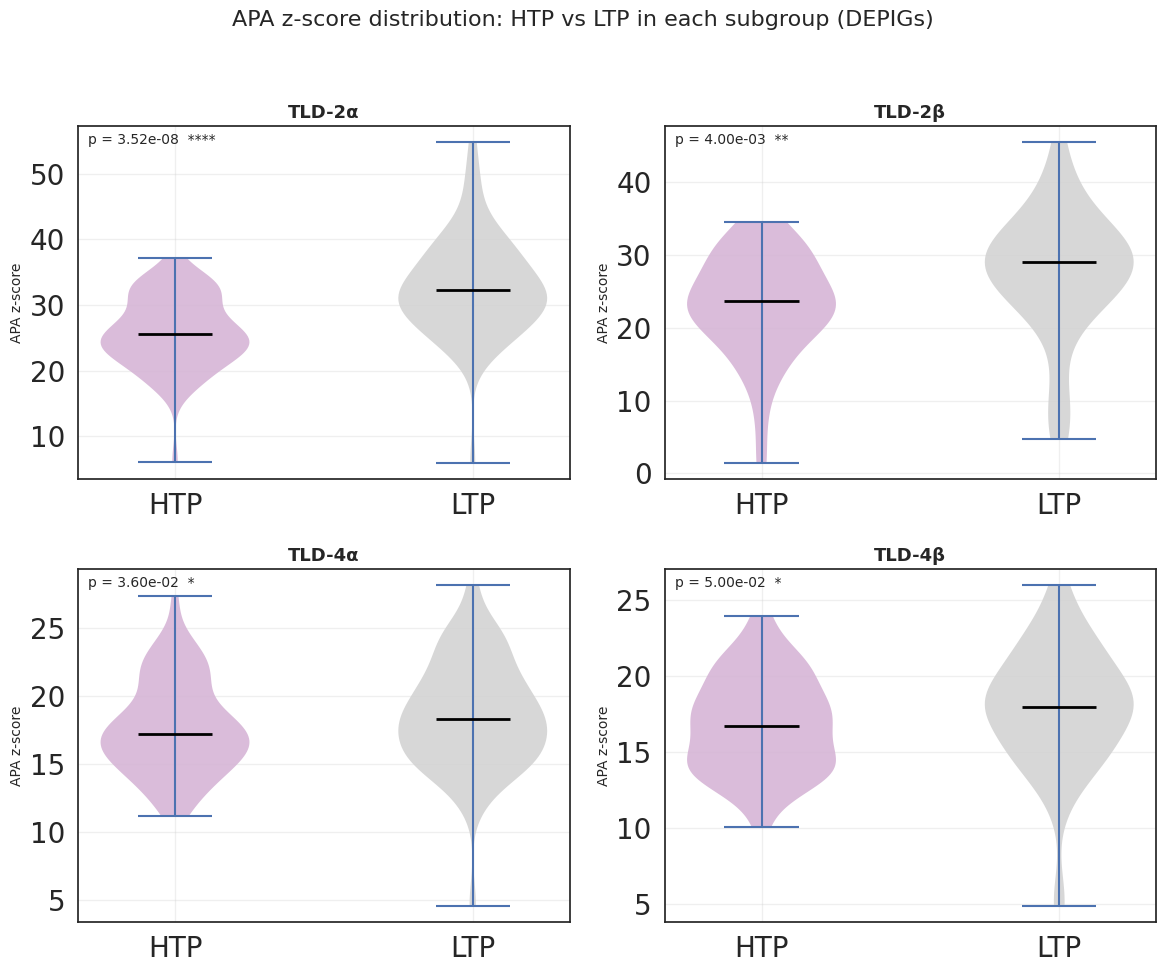

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import os

# =========================
# 辅助函数：多级显著性标注
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# =========================
# 读取数据
# =========================
file_path = "/home/lihaoxing/loop_apa_0.925/single_cell/ivf_pa_2cluster/matrix/APA_zscore_summary_ivf_deboundary.txt"
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found: {file_path}")

apa_df = pd.read_csv(file_path, sep="\t", encoding='utf-8-sig')  # 防止 BOM
apa_df = apa_df.rename(columns={'file': 'cell'})
apa_df['z_score'] = pd.to_numeric(apa_df['z_score'], errors='coerce')

# 检查是否有转换失败的行
if apa_df['z_score'].isna().any():
    print("Warning: Some z_score values could not be converted to numeric and are set to NaN.")
    # 可选择丢弃或填充

print(f"Loaded APA data: {apa_df.shape[0]} rows")

# =========================
# 定义亚群字典（请确保这些变量已定义）
# =========================
subgroups = {
    '2C-H1': subgroup_2C_H1,
    '2C-H2': subgroup_2C_H2,
    '4C-H1': subgroup_4C_H1,
    '4C-H2': subgroup_4C_H2
}

# =========================
# 提取每个亚群内 HTP (c0) 和 LTP (c1) 的 z_score 列表
# =========================
data = {}
p_values = {}
subgroup_order = ['2C-H1', '2C-H2', '4C-H1', '4C-H2']

for sg in subgroup_order:
    cells = set(subgroups[sg])
    # 筛选该亚群细胞
    sub_df = apa_df[apa_df['cell'].isin(cells)]
    # 按类型分组
    htp_vals = sub_df[sub_df['type'] == 'c0']['z_score'].values
    ltp_vals = sub_df[sub_df['type'] == 'c1']['z_score'].values
    data[sg] = {'HTP': htp_vals, 'LTP': ltp_vals}

    # 统计检验
    if len(htp_vals) > 0 and len(ltp_vals) > 0:
        p = mannwhitneyu(htp_vals, ltp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[sg] = p

# 打印结果
print("\n=== Statistical Tests (Mann-Whitney U) ===")
for sg, p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: HTP vs LTP  p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{sg}: NA")

# =========================
# 绘制小提琴图
# =========================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-H1': 'TLD-2α',
    '2C-H2': 'TLD-2β',
    '4C-H1': 'TLD-4α',
    '4C-H2': 'TLD-4β',
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]
    vals = data[sg]

    # 绘制小提琴图（两个组：HTP 和 LTP）
    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    # 中位线样式
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    # 坐标轴
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')
    ax.set_ylabel("APA z-score", fontsize=10)

    # p 值标注
    p = p_values[sg]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {get_p_annotation(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=10)

    ax.grid(alpha=0.3)

plt.suptitle("APA z-score distribution: HTP vs LTP in each subgroup (DEPIGs)",
             fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Violin_APA_HTP_LTP_subgroups_DEPIGs.svg", dpi=300, bbox_inches='tight')
plt.show()

Loaded 11605 genes from /home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_0_genes_2cluster_random99.bed
Loaded 20569 genes from /home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_1_genes_2cluster_random99.bed
HTP genes total: 11605, LTP genes total: 20554
Loaded 20289 genes from /home/lihaoxing/scRNA_expression_vs_pseudotime/expressed_genes.txt
Expressed genes (filter set): 20289
HTP valid genes: 7152, LTP valid genes: 11622
z_df 形状: (236, 3)

=== 4 Statistical Tests (Mann-Whitney U) ===
2C-iDEG1: HTP vs LTP  p = 6.00e-01  ns
2C-iDEG2: HTP vs LTP  p = 4.73e-01  ns
4C-iDEG1: HTP vs LTP  p = 1.00e+00  ns
4C-iDEG2: HTP vs LTP  p = 7.49e-01  ns


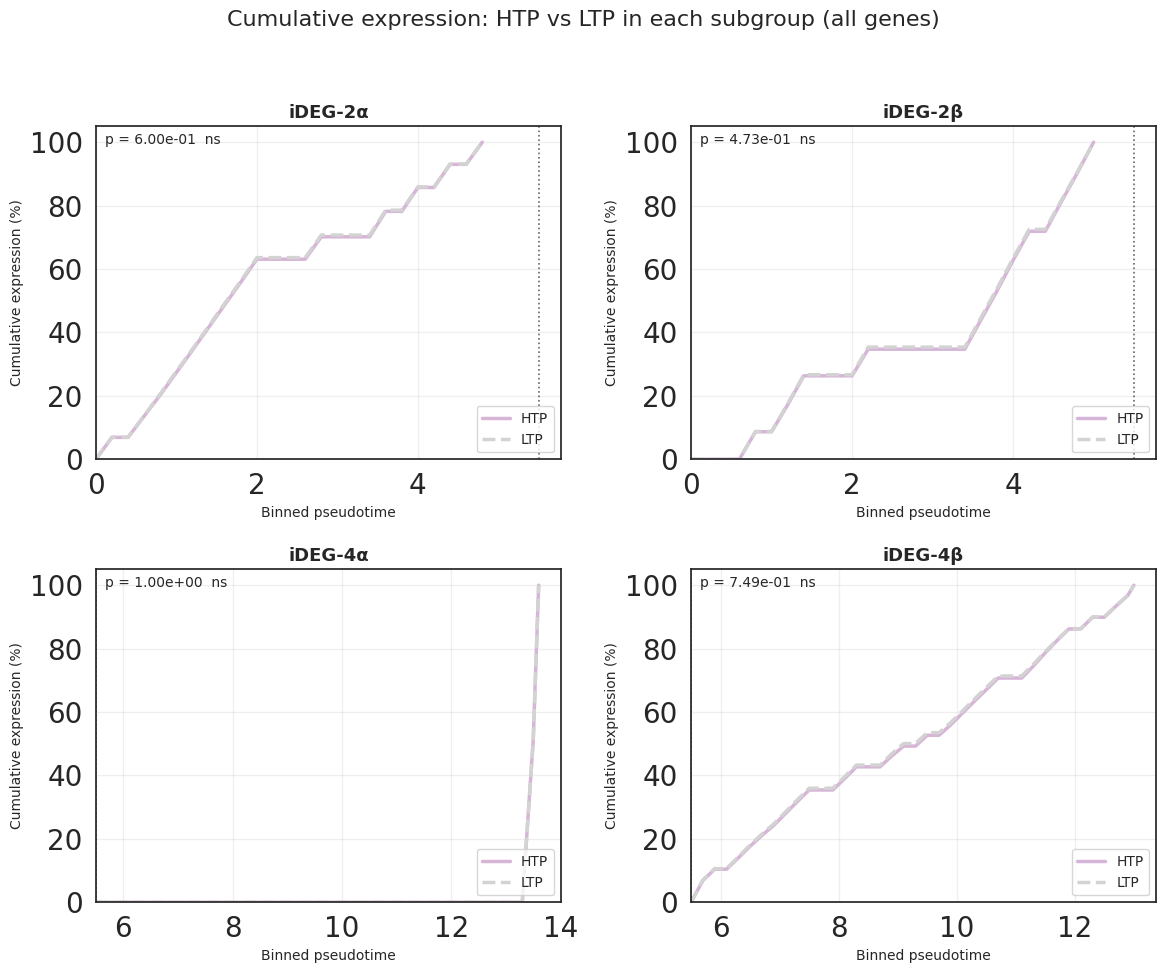

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from scipy.interpolate import interp1d
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 1. 辅助函数：读取ID列表（每行一个）
# =========================
def read_ids(filepath):
    """读取每行一个细胞ID的文本文件，返回列表"""
    with open(filepath, 'r') as f:
        ids = [line.strip() for line in f if line.strip()]
    return ids

# =========================
# 2. 读取细胞亚群（从文件）并过滤到共同细胞
# =========================
all_subgroup_files = [
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
]
all_cells = set()
for f in all_subgroup_files:
    all_cells.update(read_ids(f))
common_cells = list(all_cells)

subgroup_2C_H1 = [c for c in read_ids(all_subgroup_files[0]) if c in common_cells]
subgroup_2C_H2 = [c for c in read_ids(all_subgroup_files[1]) if c in common_cells]
subgroup_4C_H1 = [c for c in read_ids(all_subgroup_files[2]) if c in common_cells]
subgroup_4C_H2 = [c for c in read_ids(all_subgroup_files[3]) if c in common_cells]

# =========================
# 3. 读取伪时间
# =========================
time_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t", header=0
)
time_df["pseudotime"] = pd.to_numeric(time_df["pseudotime"])
sample_to_time = dict(zip(time_df["cell_id"], time_df["pseudotime"]))

# =========================
# 4. 读取表达量矩阵并计算 logCPM
# =========================
expr_all = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_118cells_readcounts.txt",
    sep="\t", index_col=0
)
total_reads = expr_all.sum(axis=0)
cpm = expr_all.div(total_reads / 1e6, axis=1)
expr_logcpm = np.log2(cpm + 1)   # 行为基因，列为细胞

# =========================
# 5. 定义 HTP 和 LTP 基因集（从 BED 文件读取）
# =========================
def load_gene_set(filepath):
    genes = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            if len(parts) >= 4:
                genes.append(parts[3])   # BED 第四列
            else:
                genes.append(parts[0])
    print(f"Loaded {len(genes)} genes from {filepath}")
    return set(genes)

HTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_0_genes_2cluster_random99.bed")
LTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_1_genes_2cluster_random99.bed")
print(f"HTP genes total: {len(HTP_genes)}, LTP genes total: {len(LTP_genes)}")

expressed_genes_file = "/home/lihaoxing/scRNA_expression_vs_pseudotime/expressed_genes.txt"
expressed_genes = load_gene_set(expressed_genes_file)
print(f"Expressed genes (filter set): {len(expressed_genes)}")

# =========================
# 6. 构建 z_df（仅使用 expressed_genes 中的基因）
# =========================
HTP_genes_valid = [g for g in HTP_genes if g in expr_logcpm.index and g in expressed_genes]
LTP_genes_valid = [g for g in LTP_genes if g in expr_logcpm.index and g in expressed_genes]
print(f"HTP valid genes: {len(HTP_genes_valid)}, LTP valid genes: {len(LTP_genes_valid)}")

expr_HTP = expr_logcpm.loc[HTP_genes_valid] if HTP_genes_valid else pd.DataFrame()
expr_LTP = expr_logcpm.loc[LTP_genes_valid] if LTP_genes_valid else pd.DataFrame()

if expr_HTP.empty or expr_LTP.empty:
    print("❌ 错误：HTP 或 LTP 有效基因数为 0，请检查基因名匹配或 expressed_genes 文件内容。")
    raise SystemExit

avg_HTP = expr_HTP.mean(axis=0)
avg_LTP = expr_LTP.mean(axis=0)

records = []
for cell in avg_HTP.index:
    records.append({'cell': cell, 'type': 'c0', 'z_score': avg_HTP[cell]})
for cell in avg_LTP.index:
    records.append({'cell': cell, 'type': 'c1', 'z_score': avg_LTP[cell]})
z_df = pd.DataFrame(records)
print(f"z_df 形状: {z_df.shape}")

# =========================
# 7. 参数 & 辅助函数
# =========================
BIN_SIZE = 0.2
min_time = 5.5

def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

def to_bin(t):
    return np.floor(t / BIN_SIZE) * BIN_SIZE

def build_binned_curve(df):
    """构建分箱均值曲线，并在最前面插入 (x0 - BIN_SIZE, 0) 起点。"""
    df = df.copy()
    df["bin"] = df["time"].apply(to_bin)
    bin_mean = df.groupby("bin")["value"].mean().reset_index()
    bin_mean = bin_mean.sort_values("bin")
    x = bin_mean["bin"].values
    v = bin_mean["value"].values
    if len(v) == 0:
        return np.array([]), np.array([]), np.array([])

    x = np.concatenate([[x[0] - BIN_SIZE], x])
    v = np.concatenate([[0.0], v])
    cum = np.cumsum(v)
    return x, v, cum

def get_curves_for_gene_set(z_df, gene_set_type, subgroups, sample_to_time,
                            time_filter, filter_value):
    data = z_df[z_df["type"] == gene_set_type].copy()
    data["time"] = data["cell"].map(sample_to_time)
    data = data.dropna(subset=["time"])
    curves = {}
    for sg_name, cell_ids in subgroups.items():
        sub = data[data["cell"].isin(cell_ids)]
        if time_filter == '<=':
            sub = sub[sub["time"] <= filter_value]
        else:
            sub = sub[sub["time"] >= filter_value]
        if sub.empty:
            continue

        cell_means = sub.groupby("cell")["z_score"].mean().reset_index()
        cell_means = cell_means.merge(sub[["cell", "time"]].drop_duplicates(), on="cell")
        df = cell_means[["time", "z_score"]].rename(columns={"z_score": "value"})

        x, _, cum = build_binned_curve(df)
        if len(cum) == 0:
            continue

        # 归一化为百分比
        total = cum[-1]
        if total == 0 or not np.isfinite(total):
            continue
        cum = (cum / total) * 100.0
        cum[0] = 0.0
        cum[-1] = 100.0

        # 网格起点：2C 从 0，4C 从 min_time
        if time_filter == '<=':
            t_start = 0.0
        else:
            t_start = float(filter_value)

        t_max = x[-1]
        if t_max <= t_start:
            continue

        n_steps = int(np.round((t_max - t_start) / BIN_SIZE))
        grid = t_start + np.arange(n_steps + 1) * BIN_SIZE
        grid[-1] = t_max

        f = interp1d(x, cum, kind='previous',
                     fill_value=(cum[0], cum[-1]), bounds_error=False)
        cum_interp = f(grid)
        cum_interp[0] = 0.0
        cum_interp[-1] = 100.0

        curves[sg_name] = (grid, cum_interp)
    return curves

subgroups = {
    '2C-iDEG1': subgroup_2C_H1,
    '2C-iDEG2': subgroup_2C_H2,
    '4C-iDEG1': subgroup_4C_H1,
    '4C-iDEG2': subgroup_4C_H2
}

# =========================
# 8. 获取 HTP (c0) 和 LTP (c1) 曲线
# =========================
curves_htp_2c = get_curves_for_gene_set(z_df, 'c0', subgroups, sample_to_time, '<=', min_time)
curves_htp_4c = get_curves_for_gene_set(z_df, 'c0', subgroups, sample_to_time, '>=', min_time)
curves_ltp_2c = get_curves_for_gene_set(z_df, 'c1', subgroups, sample_to_time, '<=', min_time)
curves_ltp_4c = get_curves_for_gene_set(z_df, 'c1', subgroups, sample_to_time, '>=', min_time)

# =========================
# 9. 只计算 4 个比较：同一亚群内 HTP vs LTP
# =========================
comparison_list = [
    ('2C-iDEG1', 'HTP', 'LTP'),
    ('2C-iDEG2', 'HTP', 'LTP'),
    ('4C-iDEG1', 'HTP', 'LTP'),
    ('4C-iDEG2', 'HTP', 'LTP')
]

p_values = {}
for sg, g1, g2 in comparison_list:
    if '2C' in sg:
        curves_h = curves_htp_2c
        curves_l = curves_ltp_2c
    else:
        curves_h = curves_htp_4c
        curves_l = curves_ltp_4c

    if sg in curves_h and sg in curves_l:
        grid_h, cum_h = curves_h[sg]
        grid_l, cum_l = curves_l[sg]
        common = np.sort(np.unique(np.concatenate([grid_h, grid_l])))
        f_h = interp1d(grid_h, cum_h, kind='previous',
                       fill_value=(cum_h[0], cum_h[-1]), bounds_error=False)
        f_l = interp1d(grid_l, cum_l, kind='previous',
                       fill_value=(cum_l[0], cum_l[-1]), bounds_error=False)
        p = mannwhitneyu(f_h(common), f_l(common), alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[(sg, g1, g2)] = p

print("\n=== 4 Statistical Tests (Mann-Whitney U) ===")
for (sg, g1, g2), p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: {g1} vs {g2}  p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{sg}: NA")

# =========================
# 10. 绘图：4个子图
# =========================
# HTP / LTP 配色
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-iDEG1': 'iDEG-2α',
    '2C-iDEG2': 'iDEG-2β',
    '4C-iDEG1': 'iDEG-4α',
    '4C-iDEG2': 'iDEG-4β',
}

subgroup_order = ['2C-iDEG1', '2C-iDEG2', '4C-iDEG1', '4C-iDEG2']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]

    if '2C' in sg:
        curves_h = curves_htp_2c
        curves_l = curves_ltp_2c
    else:
        curves_h = curves_htp_4c
        curves_l = curves_ltp_4c

    if sg in curves_h:
        grid_h, cum_h = curves_h[sg]
        ax.plot(grid_h, cum_h, color=label_colors['HTP'],
                linestyle='-', lw=2.5, label='HTP')

    if sg in curves_l:
        grid_l, cum_l = curves_l[sg]
        ax.plot(grid_l, cum_l, color=label_colors['LTP'],
                linestyle='--', lw=2.5, label='LTP')

    ax.axvline(min_time, color='black', linestyle=':', lw=1.2, alpha=0.6)

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')

    ax.set_xlabel("Binned pseudotime", fontsize=10)
    ax.set_ylabel("Cumulative expression (%)", fontsize=10)

    # x 轴起点：2C = 0，4C = min_time
    if '2C' in sg:
        ax.set_xlim(left=0)
    else:
        ax.set_xlim(left=min_time)

    # y 轴统一 0–100
    ax.set_ylim(0, 105)
    ax.set_yticks([0, 20, 40, 60, 80, 100])

    ax.legend(loc='lower right', fontsize=10, framealpha=0.8)

    key = (sg, 'HTP', 'LTP')
    p = p_values.get(key, np.nan)
    p_text = f"p = {p:.2e}  {get_p_annotation(p)}" if not np.isnan(p) else "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes,
            va='top', ha='left', fontsize=10)

    ax.grid(alpha=0.3)

fig.suptitle("Cumulative expression: HTP vs LTP in each subgroup (all genes)",
             fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig('Cumulative_expression_HTP_LTP_subgroups_percentage.svg', dpi=300, bbox_inches='tight')
plt.show()

HTP genes total: 11605, LTP genes total: 20554
Expressed genes (filter set): 20289
HTP valid genes: 7108, LTP valid genes: 11533
z_df 形状: (276, 3)

=== Statistical Tests (Mann-Whitney U) by period ===
2C: HTP vs LTP  p = 4.77e-04  ***
4C: HTP vs LTP  p = 9.73e-01  ns


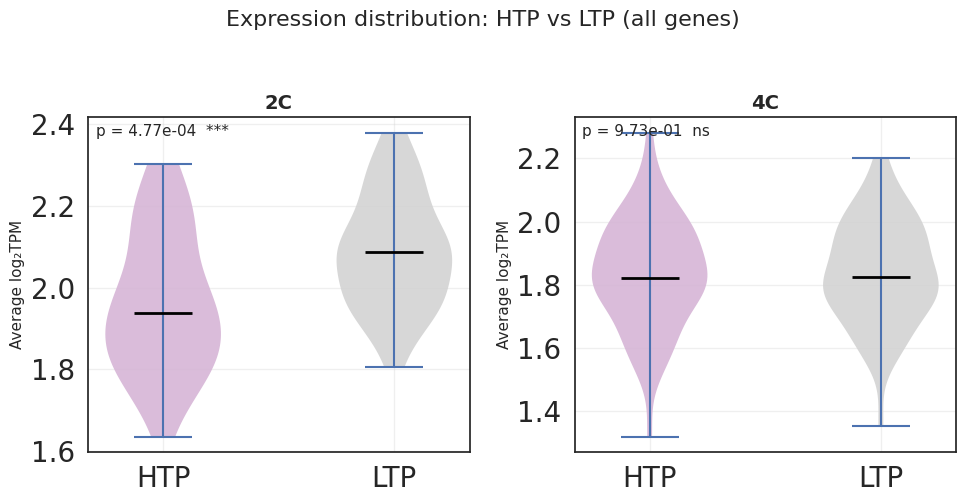

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 1. 辅助函数：读取ID列表
# =========================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        ids = [line.strip() for line in f if line.strip()]
    return ids

# =========================
# 2. 读取细胞亚群（并取并集作为共同细胞）
# =========================
all_subgroup_files = [
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
]
all_cells = set()
for f in all_subgroup_files:
    all_cells.update(read_ids(f))
common_cells = list(all_cells)

subgroup_2C_H1 = [c for c in read_ids(all_subgroup_files[0]) if c in common_cells]
subgroup_2C_H2 = [c for c in read_ids(all_subgroup_files[1]) if c in common_cells]
subgroup_4C_H1 = [c for c in read_ids(all_subgroup_files[2]) if c in common_cells]
subgroup_4C_H2 = [c for c in read_ids(all_subgroup_files[3]) if c in common_cells]

# =========================
# 3. 读取伪时间（此处不再使用）
# =========================
time_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t", header=0
)
time_df["pseudotime"] = pd.to_numeric(time_df["pseudotime"])
sample_to_time = dict(zip(time_df["cell_id"], time_df["pseudotime"]))

# =========================
# 4. 读取表达量矩阵并计算 log2TPM
# =========================
expr_all = pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt", sep="\t", index_col=0)
expr_logcpm = np.log2(expr_all + 1)

# =========================
# 5. 定义 HTP 和 LTP 基因集
# =========================
def load_gene_set(filepath):
    genes = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            if len(parts) >= 4:
                genes.append(parts[3])
            else:
                genes.append(parts[0])
    return set(genes)

HTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_0_genes_2cluster_random99.bed")
LTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_1_genes_2cluster_random99.bed")
print(f"HTP genes total: {len(HTP_genes)}, LTP genes total: {len(LTP_genes)}")

# 读取 expressed_genes 过滤集
expressed_genes_file = "/home/lihaoxing/scRNA_expression_vs_pseudotime/expressed_genes.txt"
expressed_genes = load_gene_set(expressed_genes_file)
print(f"Expressed genes (filter set): {len(expressed_genes)}")

# =========================
# 6. 构建 z_df（每个细胞 c0 和 c1 的平均表达）
# =========================
HTP_genes_valid = [g for g in HTP_genes if g in expr_logcpm.index and g in expressed_genes]
LTP_genes_valid = [g for g in LTP_genes if g in expr_logcpm.index and g in expressed_genes]
print(f"HTP valid genes: {len(HTP_genes_valid)}, LTP valid genes: {len(LTP_genes_valid)}")

expr_HTP = expr_logcpm.loc[HTP_genes_valid] if HTP_genes_valid else pd.DataFrame()
expr_LTP = expr_logcpm.loc[LTP_genes_valid] if LTP_genes_valid else pd.DataFrame()

if expr_HTP.empty or expr_LTP.empty:
    print("❌ 错误：HTP 或 LTP 有效基因数为 0，请检查基因名匹配或 expressed_genes 文件内容。")
    raise SystemExit

avg_HTP = expr_HTP.mean(axis=0)
avg_LTP = expr_LTP.mean(axis=0)

records = []
for cell in avg_HTP.index:
    records.append({'cell': cell, 'type': 'c0', 'z_score': avg_HTP[cell]})
for cell in avg_LTP.index:
    records.append({'cell': cell, 'type': 'c1', 'z_score': avg_LTP[cell]})
z_df = pd.DataFrame(records)
print(f"z_df 形状: {z_df.shape}")

# =========================
# 7. 合并亚群为时期（2C 和 4C）
# =========================
cells_2C = subgroup_2C_H1 + subgroup_2C_H2
cells_4C = subgroup_4C_H1 + subgroup_4C_H2

periods = {
    '2C': cells_2C,
    '4C': cells_4C
}

# =========================
# 8. 提取每个时期内 HTP/LTP 的 z_score 并做统计检验
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

period_order = ['2C', '4C']
data = {}
p_values = {}

for period in period_order:
    cells = set(periods[period])
    sub_df = z_df[z_df['cell'].isin(cells)]
    htp_vals = sub_df[sub_df['type'] == 'c0']['z_score'].values
    ltp_vals = sub_df[sub_df['type'] == 'c1']['z_score'].values
    data[period] = {'HTP': htp_vals, 'LTP': ltp_vals}

    if len(htp_vals) > 0 and len(ltp_vals) > 0:
        p = mannwhitneyu(htp_vals, ltp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[period] = p

print("\n=== Statistical Tests (Mann-Whitney U) by period ===")
for period, p in p_values.items():
    if not np.isnan(p):
        print(f"{period}: HTP vs LTP  p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{period}: NA")

# =========================
# 9. 绘制小提琴图（一行两列）
# =========================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for idx, period in enumerate(period_order):
    ax = axes[idx]
    vals = data[period]

    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])
    ax.set_title(period, fontsize=14, fontweight='bold')
    ax.set_ylabel("Average log₂TPM", fontsize=11)

    p = p_values[period]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {get_p_annotation(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=11)

    ax.grid(alpha=0.3)

plt.suptitle("Expression distribution: HTP vs LTP (all genes)", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("Violin_expression_HTP_LTP_by_period.svg", dpi=300, bbox_inches='tight')
plt.show()

HTP genes total: 11605, LTP genes total: 20554
Expressed genes (filter set): 20289
HTP valid genes: 7108, LTP valid genes: 11533
z_df 形状: (276, 3)

=== All pairwise comparisons (Mann-Whitney U) ===
2C_HTP vs 2C_LTP : p = 4.77e-04  ***
4C_HTP vs 4C_LTP : p = 9.73e-01  ns
2C_HTP vs 4C_HTP : p = 1.44e-03  **
2C_LTP vs 4C_LTP : p = 1.29e-10  ****


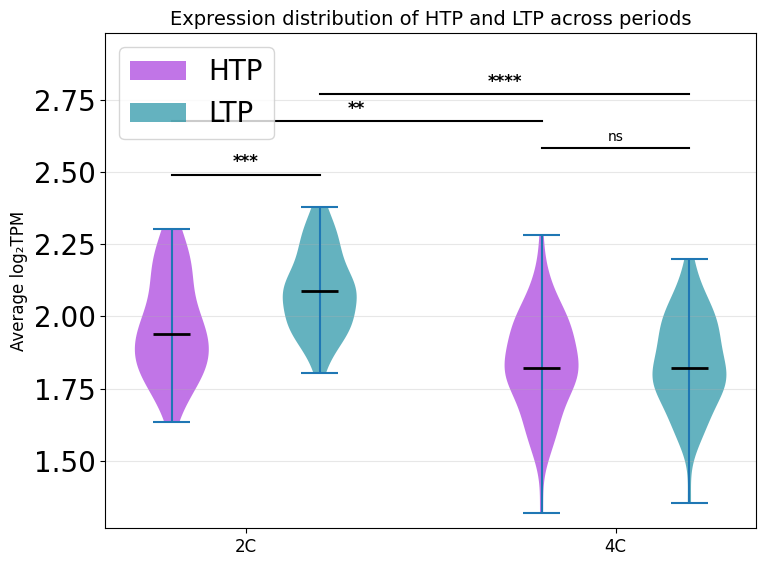

In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from itertools import combinations

# =========================
# 1. 辅助函数：读取ID列表
# =========================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        ids = [line.strip() for line in f if line.strip()]
    return ids

# =========================
# 2. 读取细胞亚群（并取并集作为共同细胞）
# =========================
all_subgroup_files = [
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
]
all_cells = set()
for f in all_subgroup_files:
    all_cells.update(read_ids(f))
common_cells = list(all_cells)

subgroup_2C_H1 = [c for c in read_ids(all_subgroup_files[0]) if c in common_cells]
subgroup_2C_H2 = [c for c in read_ids(all_subgroup_files[1]) if c in common_cells]
subgroup_4C_H1 = [c for c in read_ids(all_subgroup_files[2]) if c in common_cells]
subgroup_4C_H2 = [c for c in read_ids(all_subgroup_files[3]) if c in common_cells]

# =========================
# 3. 读取伪时间（此处不再使用）
# =========================
time_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t", header=0
)
time_df["pseudotime"] = pd.to_numeric(time_df["pseudotime"])
sample_to_time = dict(zip(time_df["cell_id"], time_df["pseudotime"]))

# =========================
# 4. 读取表达量矩阵并计算 log2TPM
# =========================
expr_all = pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt", sep="\t", index_col=0)
expr_logcpm = np.log2(expr_all + 1)

# =========================
# 5. 定义 HTP 和 LTP 基因集
# =========================
def load_gene_set(filepath):
    genes = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            if len(parts) >= 4:
                genes.append(parts[3])
            else:
                genes.append(parts[0])
    return set(genes)

HTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_0_genes_2cluster_random99.bed")
LTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_1_genes_2cluster_random99.bed")
print(f"HTP genes total: {len(HTP_genes)}, LTP genes total: {len(LTP_genes)}")

# 读取 expressed_genes 过滤集
expressed_genes_file = "/home/lihaoxing/scRNA_expression_vs_pseudotime/expressed_genes.txt"
expressed_genes = load_gene_set(expressed_genes_file)
print(f"Expressed genes (filter set): {len(expressed_genes)}")

# =========================
# 6. 构建 z_df（每个细胞 c0 和 c1 的平均表达）
# =========================
HTP_genes_valid = [g for g in HTP_genes if g in expr_logcpm.index and g in expressed_genes]
LTP_genes_valid = [g for g in LTP_genes if g in expr_logcpm.index and g in expressed_genes]
print(f"HTP valid genes: {len(HTP_genes_valid)}, LTP valid genes: {len(LTP_genes_valid)}")

expr_HTP = expr_logcpm.loc[HTP_genes_valid] if HTP_genes_valid else pd.DataFrame()
expr_LTP = expr_logcpm.loc[LTP_genes_valid] if LTP_genes_valid else pd.DataFrame()

if expr_HTP.empty or expr_LTP.empty:
    print("❌ 错误：HTP 或 LTP 有效基因数为 0，请检查基因名匹配或 expressed_genes 文件内容。")
    raise SystemExit

avg_HTP = expr_HTP.mean(axis=0)
avg_LTP = expr_LTP.mean(axis=0)

records = []
for cell in avg_HTP.index:
    records.append({'cell': cell, 'type': 'c0', 'z_score': avg_HTP[cell]})
for cell in avg_LTP.index:
    records.append({'cell': cell, 'type': 'c1', 'z_score': avg_LTP[cell]})
z_df = pd.DataFrame(records)
print(f"z_df 形状: {z_df.shape}")


# =========================
# 7. 合并亚群为时期（2C 和 4C）
# =========================
cells_2C = subgroup_2C_H1 + subgroup_2C_H2
cells_4C = subgroup_4C_H1 + subgroup_4C_H2

periods = {
    '2C': cells_2C,
    '4C': cells_4C
}

# =========================
# 8. 提取数据并计算所有需要的统计检验
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# 我们定义四组数据：
groups = {}
for period in ['2C', '4C']:
    cells = set(periods[period])
    sub_df = z_df[z_df['cell'].isin(cells)]
    groups[f"{period}_HTP"] = sub_df[sub_df['type'] == 'c0']['z_score'].values
    groups[f"{period}_LTP"] = sub_df[sub_df['type'] == 'c1']['z_score'].values

# 需要比较的配对：
# 1) 同期 HTP vs LTP: 2C_HTP vs 2C_LTP, 4C_HTP vs 4C_LTP
# 2) 同基因集跨时期: HTP_2C vs HTP_4C, LTP_2C vs LTP_4C
pairwise_comparisons = [
    ('2C_HTP', '2C_LTP'),
    ('4C_HTP', '4C_LTP'),
    ('2C_HTP', '4C_HTP'),
    ('2C_LTP', '4C_LTP')
]

p_values = {}
for g1, g2 in pairwise_comparisons:
    d1 = groups[g1]
    d2 = groups[g2]
    if len(d1) > 0 and len(d2) > 0:
        p = mannwhitneyu(d1, d2, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[(g1, g2)] = p

print("\n=== All pairwise comparisons (Mann-Whitney U) ===")
for (g1, g2), p in p_values.items():
    if not np.isnan(p):
        print(f"{g1} vs {g2} : p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{g1} vs {g2} : NA")

# =========================
# 9. 绘制分组小提琴图（单图）
# =========================
fig, ax = plt.subplots(figsize=(8, 6))

# 定义位置和颜色
periods_order = ['2C', '4C']
htp_color = '#A73BDD'   # HTP
ltp_color = '#2292A4'   # LTP

# 构建四组数据及其位置
positions = [1, 2, 3.5, 4.5]  # 让两组之间留出间隔
group_labels = ['2C-HTP', '2C-LTP', '4C-HTP', '4C-LTP']
data_to_plot = [groups['2C_HTP'], groups['2C_LTP'], groups['4C_HTP'], groups['4C_LTP']]
colors = [htp_color, ltp_color, htp_color, ltp_color]

# 绘制小提琴图
parts = ax.violinplot(data_to_plot, positions=positions, showmeans=False, showmedians=True)

# 设置颜色和透明度
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[i])
    pc.set_alpha(0.7)
    pc.set_edgecolor('none')
parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(2)

# 添加分组背景框（可选）
# ax.axvspan(0.5, 2.5, alpha=0.1, color='gray')
# ax.axvspan(3.0, 5.0, alpha=0.1, color='gray')

ax.set_xticks([1.5, 4.0])
ax.set_xticklabels(['2C', '4C'], fontsize=12)
ax.set_ylabel("Average log₂TPM", fontsize=12)
ax.set_title("Expression distribution of HTP and LTP across periods", fontsize=14)

# 添加图例（手动创建）
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=htp_color, alpha=0.7, label='HTP'),
                   Patch(facecolor=ltp_color, alpha=0.7, label='LTP')]
ax.legend(handles=legend_elements, loc='upper left')

# ----- 添加统计注释（用线和星号）-----
# 定义几个需要标注的比较：我们选取所有配对，但为了避免拥挤，可以只标注显著的，或者全部标注。
# 这里我们标注四个比较，分别放在图的上方不同高度。

# 先定义每个组的 x 坐标（用于画线）
x_pos = { '2C_HTP': 1, '2C_LTP': 2, '4C_HTP': 3.5, '4C_LTP': 4.5 }

# 按 p 值从小到大排序，决定 y 轴高度（从上往下）
comparison_list = [
    ('2C_HTP', '2C_LTP', '同期 2C'),
    ('4C_HTP', '4C_LTP', '同期 4C'),
    ('2C_HTP', '4C_HTP', 'HTP 跨期'),
    ('2C_LTP', '4C_LTP', 'LTP 跨期')
]

# 获取当前 y 轴范围
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min
# 从顶部开始，依次增加高度
y_base = y_max + 0.05 * y_range
y_step = 0.08 * y_range

for i, (g1, g2, label) in enumerate(comparison_list):
    p = p_values[(g1, g2)]
    if np.isnan(p):
        continue
    x1 = x_pos[g1]
    x2 = x_pos[g2]
    y = y_base + i * y_step
    # 画横线连接两个组
    ax.plot([x1, x2], [y, y], color='k', linewidth=1.5)
    # 添加星号
    if p < 0.05:
        star = get_p_annotation(p)
        ax.text((x1+x2)/2, y+0.01*y_range, star, ha='center', va='bottom', fontsize=12, fontweight='bold')
    else:
        ax.text((x1+x2)/2, y+0.01*y_range, 'ns', ha='center', va='bottom', fontsize=10)

# 调整 y 轴上限，确保注释可见
ax.set_ylim(y_min, y_base + len(comparison_list)*y_step + 0.1*y_range)

# 添加网格
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("Violin_expression_HTP_LTP_combined.svg", dpi=300, bbox_inches='tight')
plt.show()

HTP genes total: 11605, LTP genes total: 20554
Expressed genes (filter set): 3314
HTP valid genes: 1323, LTP valid genes: 1763
z_df 形状: (276, 3)

=== Statistical Tests (Mann-Whitney U) by period ===
2C: HTP vs LTP  p=0.0465  *
4C: HTP vs LTP  p=0.5000  ns


/home/lihaoxing/tmp/ipykernel_990722/2896210910.py:206: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_990722/2896210910.py:248: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['HTP', 'LTP'], fontsize=12)
/home/lihaoxing/tmp/ipykernel_990722/2896210910.py:206: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_990722/2896210910.py:248: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['HTP', 'LTP'], fontsize=12)


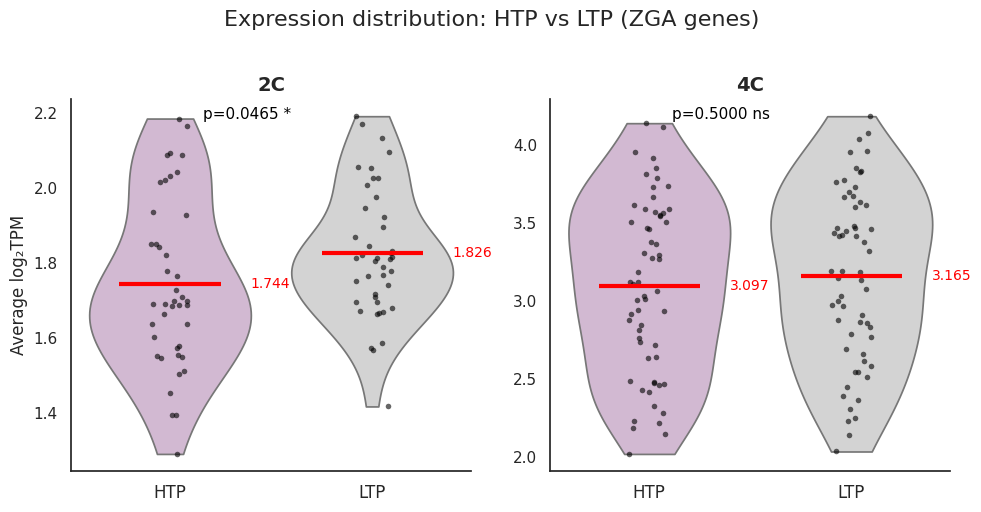

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import seaborn as sns

# =========================
# 0. 全局参数
# =========================
ALPHA = 0.05

# =========================
# 1. 辅助函数：读取ID列表
# =========================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        ids = [line.strip() for line in f if line.strip()]
    return ids

# =========================
# 2. 读取细胞亚群（并取并集作为共同细胞）
# =========================
all_subgroup_files = [
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
]
all_cells = set()
for f in all_subgroup_files:
    all_cells.update(read_ids(f))
common_cells = list(all_cells)

subgroup_2C_H1 = [c for c in read_ids(all_subgroup_files[0]) if c in common_cells]
subgroup_2C_H2 = [c for c in read_ids(all_subgroup_files[1]) if c in common_cells]
subgroup_4C_H1 = [c for c in read_ids(all_subgroup_files[2]) if c in common_cells]
subgroup_4C_H2 = [c for c in read_ids(all_subgroup_files[3]) if c in common_cells]

# =========================
# 3. 读取伪时间（此处不再使用）
# =========================
time_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t", header=0
)
time_df["pseudotime"] = pd.to_numeric(time_df["pseudotime"], errors="coerce")
time_df = time_df.dropna(subset=["pseudotime"])
sample_to_time = dict(zip(time_df["cell_id"], time_df["pseudotime"]))

# =========================
# 4. 读取表达量矩阵并计算 log2TPM
# =========================
expr_all = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt",
    sep="\t", index_col=0
)
expr_logcpm = np.log2(expr_all + 1)

# =========================
# 5. 定义 HTP 和 LTP 基因集
# =========================
def load_gene_set(filepath):
    genes = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            if len(parts) >= 4:
                genes.append(parts[3])
            else:
                genes.append(parts[0])
    return set(genes)

HTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_0_genes_2cluster_random99.bed")
LTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_1_genes_2cluster_random99.bed")
print(f"HTP genes total: {len(HTP_genes)}, LTP genes total: {len(LTP_genes)}")

# 读取 expressed_genes 过滤集
expressed_genes_file = "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_ZGAid.txt"
expressed_genes = load_gene_set(expressed_genes_file)
print(f"Expressed genes (filter set): {len(expressed_genes)}")

# =========================
# 6. 构建 z_df（每个细胞 c0 和 c1 的平均表达）
# =========================
HTP_genes_valid = [g for g in HTP_genes if g in expr_logcpm.index and g in expressed_genes]
LTP_genes_valid = [g for g in LTP_genes if g in expr_logcpm.index and g in expressed_genes]
print(f"HTP valid genes: {len(HTP_genes_valid)}, LTP valid genes: {len(LTP_genes_valid)}")

expr_HTP = expr_logcpm.loc[HTP_genes_valid] if HTP_genes_valid else pd.DataFrame()
expr_LTP = expr_logcpm.loc[LTP_genes_valid] if LTP_genes_valid else pd.DataFrame()

if expr_HTP.empty or expr_LTP.empty:
    print("错误：HTP 或 LTP 有效基因数为 0，请检查基因名匹配或 expressed_genes 文件内容。")
    raise SystemExit

avg_HTP = expr_HTP.mean(axis=0)
avg_LTP = expr_LTP.mean(axis=0)

records = []
for cell in avg_HTP.index:
    records.append({'cell': cell, 'type': 'c0', 'z_score': avg_HTP[cell]})
for cell in avg_LTP.index:
    records.append({'cell': cell, 'type': 'c1', 'z_score': avg_LTP[cell]})
z_df = pd.DataFrame(records)
print(f"z_df 形状: {z_df.shape}")

# =========================
# 7. 合并亚群为时期（2C 和 4C）
# =========================
cells_2C = subgroup_2C_H1 + subgroup_2C_H2
cells_4C = subgroup_4C_H1 + subgroup_4C_H2

periods = {
    '2C': cells_2C,
    '4C': cells_4C
}

# =========================
# 8. p 值格式化（不用 e 表示）
# =========================
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if p is None or np.isnan(p):
        return "p=NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def get_p_annotation(p):
    if p is None or np.isnan(p):
        return "ns"
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

# =========================
# 9. 提取每个时期内 HTP/LTP 的 z_score 并做统计检验
# =========================
period_order = ['2C', '4C']
data = {}
p_values = {}

for period in period_order:
    cells = set(periods[period])
    sub_df = z_df[z_df['cell'].isin(cells)]
    htp_vals = sub_df[sub_df['type'] == 'c0']['z_score'].values
    ltp_vals = sub_df[sub_df['type'] == 'c1']['z_score'].values
    data[period] = {'HTP': htp_vals, 'LTP': ltp_vals}

    if len(htp_vals) > 0 and len(ltp_vals) > 0:
        p = mannwhitneyu(htp_vals, ltp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[period] = p

print("\n=== Statistical Tests (Mann-Whitney U) by period ===")
for period, p in p_values.items():
    print(f"{period}: HTP vs LTP  {format_p_value(p)}  {get_p_annotation(p)}")

# =========================
# 10. 绘制小提琴图（一行两列，风格优化）
# =========================
sns.set(style="white")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

plot_data_list = []
for period in period_order:
    cells = set(periods[period])
    sub_df = z_df[z_df['cell'].isin(cells)].copy()
    sub_df['period'] = period
    sub_df['type_label'] = sub_df['type'].map({'c0': 'HTP', 'c1': 'LTP'})
    plot_data_list.append(sub_df)
plot_df = pd.concat(plot_data_list, ignore_index=True)

# 统一配色：HTP / LTP
htp_ltp_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=False)

for idx, period in enumerate(period_order):
    ax = axes[idx]
    df_sub = plot_df[plot_df['period'] == period]

    # 小提琴
    sns.violinplot(
        x='type_label',
        y='z_score',
        data=df_sub,
        order=['HTP', 'LTP'],
        palette=htp_ltp_colors,
        inner=None,
        cut=0,
        ax=ax
    )

    # 散点
    sns.stripplot(
        x='type_label',
        y='z_score',
        data=df_sub,
        order=['HTP', 'LTP'],
        color='black',
        size=4,
        alpha=0.6,
        ax=ax
    )

    # 红色均值线 + 数值
    group_means = df_sub.groupby('type_label')['z_score'].mean()
    for i, label in enumerate(['HTP', 'LTP']):
        mean_val = group_means[label]
        ax.hlines(mean_val, i - 0.25, i + 0.25,
                  color='red', linewidth=3, zorder=5)
        ax.text(i + 0.4, mean_val, f"{mean_val:.3f}",
                ha='left', va='center', fontsize=10, color='red')

    # p 值标注（不用 e 表示）
    p = p_values[period]
    p_text = f"{format_p_value(p)} {get_p_annotation(p)}"
    ax.text(0.55, 0.98, p_text, transform=ax.transAxes,
            va='top', ha='right', fontsize=11, color='black')

    # 坐标轴美化
    ax.set_title(period, fontsize=14, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Average log₂TPM" if idx == 0 else "", fontsize=12)
    ax.set_xticklabels(['HTP', 'LTP'], fontsize=12)
    ax.grid(False)
    sns.despine(ax=ax)

plt.suptitle("Expression distribution: HTP vs LTP (ZGA genes)", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("Violin_expression_HTP_LTP_by_period_optimized.svg",
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

HTP genes total: 11605, LTP genes total: 20554
Expressed genes (filter set): 3314
HTP valid genes: 1323, LTP valid genes: 1763
z_df 形状: (276, 3)

=== All pairwise comparisons (Mann-Whitney U) ===
2C_HTP vs 2C_LTP : p = 4.65e-02  *
4C_HTP vs 4C_LTP : p = 5.00e-01  ns
2C_HTP vs 4C_HTP : p = 1.85e-17  ****
2C_LTP vs 4C_LTP : p = 1.75e-17  ****

=== Mean expression levels (log2TPM) ===
2C_HTP: 1.7443
2C_LTP: 1.8258
4C_HTP: 3.0973
4C_LTP: 3.1646

=== Fold changes between periods for same gene set ===
HTP (4C vs 2C): log2FC = 1.3531,  fold change = 2.5546
LTP (4C vs 2C): log2FC = 1.3388,  fold change = 2.5295


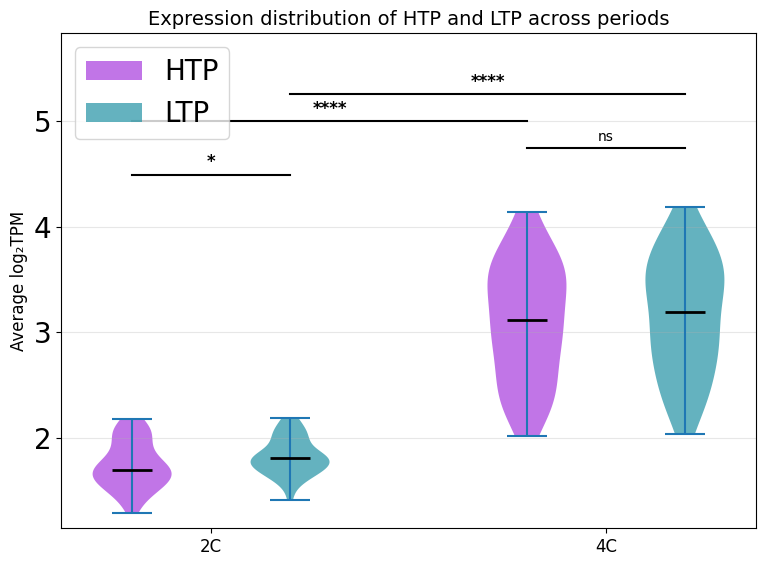

In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from itertools import combinations

# =========================
# 1. 辅助函数：读取ID列表
# =========================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        ids = [line.strip() for line in f if line.strip()]
    return ids

# =========================
# 2. 读取细胞亚群（并取并集作为共同细胞）
# =========================
all_subgroup_files = [
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
]
all_cells = set()
for f in all_subgroup_files:
    all_cells.update(read_ids(f))
common_cells = list(all_cells)

subgroup_2C_H1 = [c for c in read_ids(all_subgroup_files[0]) if c in common_cells]
subgroup_2C_H2 = [c for c in read_ids(all_subgroup_files[1]) if c in common_cells]
subgroup_4C_H1 = [c for c in read_ids(all_subgroup_files[2]) if c in common_cells]
subgroup_4C_H2 = [c for c in read_ids(all_subgroup_files[3]) if c in common_cells]

# =========================
# 3. 读取伪时间（此处不再使用）
# =========================
time_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t", header=0
)
time_df["pseudotime"] = pd.to_numeric(time_df["pseudotime"])
sample_to_time = dict(zip(time_df["cell_id"], time_df["pseudotime"]))

# =========================
# 4. 读取表达量矩阵并计算 log2TPM
# =========================
expr_all = pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt", sep="\t", index_col=0)
expr_logcpm = np.log2(expr_all + 1)

# =========================
# 5. 定义 HTP 和 LTP 基因集
# =========================
def load_gene_set(filepath):
    genes = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            if len(parts) >= 4:
                genes.append(parts[3])
            else:
                genes.append(parts[0])
    return set(genes)

HTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_0_genes_2cluster_random99.bed")
LTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_1_genes_2cluster_random99.bed")
print(f"HTP genes total: {len(HTP_genes)}, LTP genes total: {len(LTP_genes)}")

# 读取 expressed_genes 过滤集
expressed_genes_file = "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_ZGAid.txt"
expressed_genes = load_gene_set(expressed_genes_file)
print(f"Expressed genes (filter set): {len(expressed_genes)}")

# =========================
# 6. 构建 z_df（每个细胞 c0 和 c1 的平均表达）
# =========================
HTP_genes_valid = [g for g in HTP_genes if g in expr_logcpm.index and g in expressed_genes]
LTP_genes_valid = [g for g in LTP_genes if g in expr_logcpm.index and g in expressed_genes]
print(f"HTP valid genes: {len(HTP_genes_valid)}, LTP valid genes: {len(LTP_genes_valid)}")

expr_HTP = expr_logcpm.loc[HTP_genes_valid] if HTP_genes_valid else pd.DataFrame()
expr_LTP = expr_logcpm.loc[LTP_genes_valid] if LTP_genes_valid else pd.DataFrame()

if expr_HTP.empty or expr_LTP.empty:
    print("❌ 错误：HTP 或 LTP 有效基因数为 0，请检查基因名匹配或 expressed_genes 文件内容。")
    raise SystemExit

avg_HTP = expr_HTP.mean(axis=0)
avg_LTP = expr_LTP.mean(axis=0)

records = []
for cell in avg_HTP.index:
    records.append({'cell': cell, 'type': 'c0', 'z_score': avg_HTP[cell]})
for cell in avg_LTP.index:
    records.append({'cell': cell, 'type': 'c1', 'z_score': avg_LTP[cell]})
z_df = pd.DataFrame(records)
print(f"z_df 形状: {z_df.shape}")


# =========================
# 7. 合并亚群为时期（2C 和 4C）
# =========================
cells_2C = subgroup_2C_H1 + subgroup_2C_H2
cells_4C = subgroup_4C_H1 + subgroup_4C_H2

periods = {
    '2C': cells_2C,
    '4C': cells_4C
}

# =========================
# 8. 提取数据并计算所有需要的统计检验
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# 我们定义四组数据：
groups = {}
for period in ['2C', '4C']:
    cells = set(periods[period])
    sub_df = z_df[z_df['cell'].isin(cells)]
    groups[f"{period}_HTP"] = sub_df[sub_df['type'] == 'c0']['z_score'].values
    groups[f"{period}_LTP"] = sub_df[sub_df['type'] == 'c1']['z_score'].values

# 需要比较的配对：
# 1) 同期 HTP vs LTP: 2C_HTP vs 2C_LTP, 4C_HTP vs 4C_LTP
# 2) 同基因集跨时期: HTP_2C vs HTP_4C, LTP_2C vs LTP_4C
pairwise_comparisons = [
    ('2C_HTP', '2C_LTP'),
    ('4C_HTP', '4C_LTP'),
    ('2C_HTP', '4C_HTP'),
    ('2C_LTP', '4C_LTP')
]

p_values = {}
for g1, g2 in pairwise_comparisons:
    d1 = groups[g1]
    d2 = groups[g2]
    if len(d1) > 0 and len(d2) > 0:
        p = mannwhitneyu(d1, d2, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[(g1, g2)] = p

print("\n=== All pairwise comparisons (Mann-Whitney U) ===")
for (g1, g2), p in p_values.items():
    if not np.isnan(p):
        print(f"{g1} vs {g2} : p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{g1} vs {g2} : NA")

# =========================
# 9. 绘制分组小提琴图（单图）
# =========================
fig, ax = plt.subplots(figsize=(8, 6))

# 定义位置和颜色
periods_order = ['2C', '4C']
htp_color = '#A73BDD'   # HTP
ltp_color = '#2292A4'   # LTP

# 构建四组数据及其位置
positions = [1, 2, 3.5, 4.5]  # 让两组之间留出间隔
group_labels = ['2C-HTP', '2C-LTP', '4C-HTP', '4C-LTP']
data_to_plot = [groups['2C_HTP'], groups['2C_LTP'], groups['4C_HTP'], groups['4C_LTP']]
colors = [htp_color, ltp_color, htp_color, ltp_color]

# 绘制小提琴图
parts = ax.violinplot(data_to_plot, positions=positions, showmeans=False, showmedians=True)

# 设置颜色和透明度
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[i])
    pc.set_alpha(0.7)
    pc.set_edgecolor('none')
parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(2)

# 添加分组背景框（可选）
# ax.axvspan(0.5, 2.5, alpha=0.1, color='gray')
# ax.axvspan(3.0, 5.0, alpha=0.1, color='gray')

ax.set_xticks([1.5, 4.0])
ax.set_xticklabels(['2C', '4C'], fontsize=12)
ax.set_ylabel("Average log₂TPM", fontsize=12)
ax.set_title("Expression distribution of HTP and LTP across periods", fontsize=14)

# 添加图例（手动创建）
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=htp_color, alpha=0.7, label='HTP'),
                   Patch(facecolor=ltp_color, alpha=0.7, label='LTP')]
ax.legend(handles=legend_elements, loc='upper left')

# ----- 添加统计注释（用线和星号）-----
# 定义几个需要标注的比较：我们选取所有配对，但为了避免拥挤，可以只标注显著的，或者全部标注。
# 这里我们标注四个比较，分别放在图的上方不同高度。

# 先定义每个组的 x 坐标（用于画线）
x_pos = { '2C_HTP': 1, '2C_LTP': 2, '4C_HTP': 3.5, '4C_LTP': 4.5 }

# 按 p 值从小到大排序，决定 y 轴高度（从上往下）
comparison_list = [
    ('2C_HTP', '2C_LTP', '同期 2C'),
    ('4C_HTP', '4C_LTP', '同期 4C'),
    ('2C_HTP', '4C_HTP', 'HTP 跨期'),
    ('2C_LTP', '4C_LTP', 'LTP 跨期')
]

# 获取当前 y 轴范围
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min
# 从顶部开始，依次增加高度
y_base = y_max + 0.05 * y_range
y_step = 0.08 * y_range

for i, (g1, g2, label) in enumerate(comparison_list):
    p = p_values[(g1, g2)]
    if np.isnan(p):
        continue
    x1 = x_pos[g1]
    x2 = x_pos[g2]
    y = y_base + i * y_step
    # 画横线连接两个组
    ax.plot([x1, x2], [y, y], color='k', linewidth=1.5)
    # 添加星号
    if p < 0.05:
        star = get_p_annotation(p)
        ax.text((x1+x2)/2, y+0.01*y_range, star, ha='center', va='bottom', fontsize=12, fontweight='bold')
    else:
        ax.text((x1+x2)/2, y+0.01*y_range, 'ns', ha='center', va='bottom', fontsize=10)

# 调整 y 轴上限，确保注释可见
ax.set_ylim(y_min, y_base + len(comparison_list)*y_step + 0.1*y_range)

# 添加网格
ax.grid(axis='y', alpha=0.3)

# =========================
# 新增：计算各组均值及跨时期倍数变化
# =========================
# 计算每个组的均值（log2TPM 的平均值）
mean_vals = {}
for key, vals in groups.items():
    mean_vals[key] = np.mean(vals) if len(vals) > 0 else np.nan

# 计算 HTP 在 4C vs 2C 的 log2FC 和线性倍数
if not np.isnan(mean_vals['4C_HTP']) and not np.isnan(mean_vals['2C_HTP']):
    log2fc_htp = mean_vals['4C_HTP'] - mean_vals['2C_HTP']
    fold_htp = 2 ** log2fc_htp
else:
    log2fc_htp = np.nan
    fold_htp = np.nan

# 计算 LTP 在 4C vs 2C 的 log2FC 和线性倍数
if not np.isnan(mean_vals['4C_LTP']) and not np.isnan(mean_vals['2C_LTP']):
    log2fc_ltp = mean_vals['4C_LTP'] - mean_vals['2C_LTP']
    fold_ltp = 2 ** log2fc_ltp
else:
    log2fc_ltp = np.nan
    fold_ltp = np.nan

# 打印结果
print("\n=== Mean expression levels (log2TPM) ===")
for key in ['2C_HTP', '2C_LTP', '4C_HTP', '4C_LTP']:
    print(f"{key}: {mean_vals[key]:.4f}")

print("\n=== Fold changes between periods for same gene set ===")
print(f"HTP (4C vs 2C): log2FC = {log2fc_htp:.4f},  fold change = {fold_htp:.4f}")
print(f"LTP (4C vs 2C): log2FC = {log2fc_ltp:.4f},  fold change = {fold_ltp:.4f}")

plt.tight_layout()
plt.savefig("Violin_expression_HTP_LTP_combined.svg", dpi=300, bbox_inches='tight')
plt.show()

HTP genes total: 11605, LTP genes total: 20554
Expressed genes (filter set): 20289
HTP valid genes: 7108, LTP valid genes: 11533
z_df 形状: (276, 3)

=== Statistical Tests (Mann-Whitney U) ===
2C-iDEG1: HTP vs LTP  p = 1.20e-05  ****
2C-iDEG2: HTP vs LTP  p = 5.64e-02  ns
4C-iDEG1: HTP vs LTP  p = 1.84e-01  ns
4C-iDEG2: HTP vs LTP  p = 5.67e-01  ns


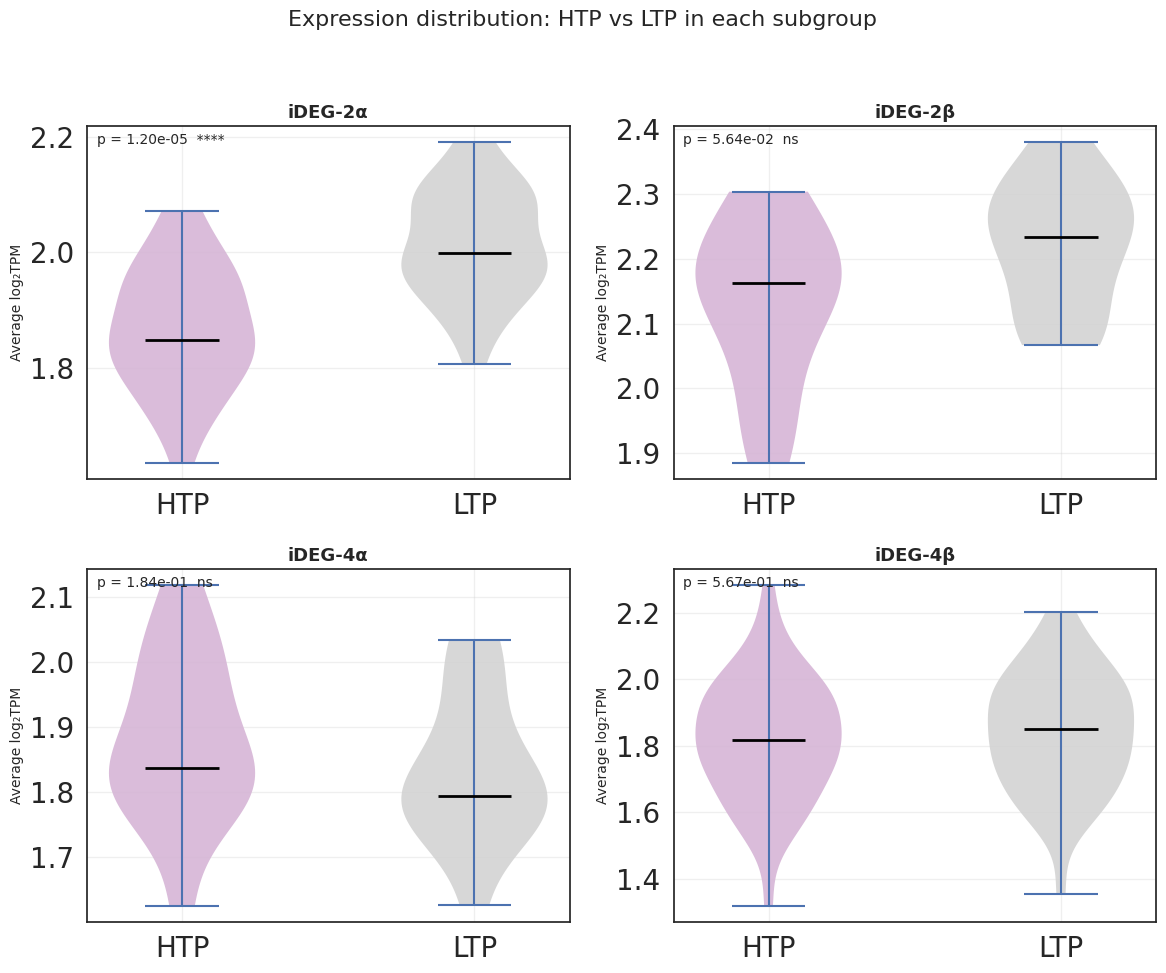

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# =========================
# 1. 辅助函数：读取ID列表
# =========================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        ids = [line.strip() for line in f if line.strip()]
    return ids

# =========================
# 2. 读取细胞亚群（并取并集作为共同细胞，此处保持原过滤逻辑）
# =========================
all_subgroup_files = [
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
]
all_cells = set()
for f in all_subgroup_files:
    all_cells.update(read_ids(f))
common_cells = list(all_cells)

subgroup_2C_H1 = [c for c in read_ids(all_subgroup_files[0]) if c in common_cells]
subgroup_2C_H2 = [c for c in read_ids(all_subgroup_files[1]) if c in common_cells]
subgroup_4C_H1 = [c for c in read_ids(all_subgroup_files[2]) if c in common_cells]
subgroup_4C_H2 = [c for c in read_ids(all_subgroup_files[3]) if c in common_cells]

# =========================
# 3. 读取伪时间（此处不再使用，但保留以防后续需要）
# =========================
time_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t", header=0
)
time_df["pseudotime"] = pd.to_numeric(time_df["pseudotime"])
sample_to_time = dict(zip(time_df["cell_id"], time_df["pseudotime"]))

# =========================
# 4. 读取表达量矩阵并计算 log2TPM
# =========================
expr_all = pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt", sep="\t", index_col=0)
expr_logcpm = np.log2(expr_all + 1)

# =========================
# 5. 定义 HTP 和 LTP 基因集
# =========================
def load_gene_set(filepath):
    genes = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            if len(parts) >= 4:
                genes.append(parts[3])
            else:
                genes.append(parts[0])
    return set(genes)

HTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_0_genes_2cluster_random99.bed")
LTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_1_genes_2cluster_random99.bed")
print(f"HTP genes total: {len(HTP_genes)}, LTP genes total: {len(LTP_genes)}")

# 读取 expressed_genes 过滤集
expressed_genes_file = "/home/lihaoxing/scRNA_expression_vs_pseudotime/expressed_genes.txt"
expressed_genes = load_gene_set(expressed_genes_file)
print(f"Expressed genes (filter set): {len(expressed_genes)}")

# =========================
# 6. 构建 z_df（每个细胞 c0 和 c1 的平均表达）
# =========================
HTP_genes_valid = [g for g in HTP_genes if g in expr_logcpm.index and g in expressed_genes]
LTP_genes_valid = [g for g in LTP_genes if g in expr_logcpm.index and g in expressed_genes]
print(f"HTP valid genes: {len(HTP_genes_valid)}, LTP valid genes: {len(LTP_genes_valid)}")

expr_HTP = expr_logcpm.loc[HTP_genes_valid] if HTP_genes_valid else pd.DataFrame()
expr_LTP = expr_logcpm.loc[LTP_genes_valid] if LTP_genes_valid else pd.DataFrame()

if expr_HTP.empty or expr_LTP.empty:
    print("❌ 错误：HTP 或 LTP 有效基因数为 0，请检查基因名匹配或 expressed_genes 文件内容。")
    raise SystemExit

avg_HTP = expr_HTP.mean(axis=0)
avg_LTP = expr_LTP.mean(axis=0)

records = []
for cell in avg_HTP.index:
    records.append({'cell': cell, 'type': 'c0', 'z_score': avg_HTP[cell]})
for cell in avg_LTP.index:
    records.append({'cell': cell, 'type': 'c1', 'z_score': avg_LTP[cell]})
z_df = pd.DataFrame(records)
print(f"z_df 形状: {z_df.shape}")

# =========================
# 7. 定义亚群字典（沿用原名称）
# =========================
subgroups = {
    '2C-iDEG1': subgroup_2C_H1,
    '2C-iDEG2': subgroup_2C_H2,
    '4C-iDEG1': subgroup_4C_H1,
    '4C-iDEG2': subgroup_4C_H2
}

# =========================
# 8. 提取每个亚群内 HTP/LTP 的 z_score 并做统计检验
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

subgroup_order = ['2C-iDEG1', '2C-iDEG2', '4C-iDEG1', '4C-iDEG2']
data = {}
p_values = {}

for sg in subgroup_order:
    cells = set(subgroups[sg])
    sub_df = z_df[z_df['cell'].isin(cells)]
    htp_vals = sub_df[sub_df['type'] == 'c0']['z_score'].values
    ltp_vals = sub_df[sub_df['type'] == 'c1']['z_score'].values
    data[sg] = {'HTP': htp_vals, 'LTP': ltp_vals}

    if len(htp_vals) > 0 and len(ltp_vals) > 0:
        p = mannwhitneyu(htp_vals, ltp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[sg] = p

print("\n=== Statistical Tests (Mann-Whitney U) ===")
for sg, p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: HTP vs LTP  p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{sg}: NA")

# =========================
# 9. 绘制小提琴图
# =========================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-iDEG1': 'iDEG-2α',
    '2C-iDEG2': 'iDEG-2β',
    '4C-iDEG1': 'iDEG-4α',
    '4C-iDEG2': 'iDEG-4β',
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]
    vals = data[sg]

    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')
    ax.set_ylabel("Average log₂TPM", fontsize=10)

    p = p_values[sg]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {get_p_annotation(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=10)

    ax.grid(alpha=0.3)

plt.suptitle("Expression distribution: HTP vs LTP in each subgroup",
             fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Violin_expression_HTP_LTP_subgroups_all.svg", dpi=300, bbox_inches='tight')
plt.show()

HTP genes total: 11605, LTP genes total: 20554
Expressed genes (filter set): 3503
HTP valid genes: 857, LTP valid genes: 1368
z_df 形状: (276, 3)

=== Statistical Tests (Mann-Whitney U) ===
2C-iDEG1: HTP vs LTP  p = 5.74e-07  ****
2C-iDEG2: HTP vs LTP  p = 1.61e-02  *
4C-iDEG1: HTP vs LTP  p = 1.87e-03  **
4C-iDEG2: HTP vs LTP  p = 4.54e-02  *


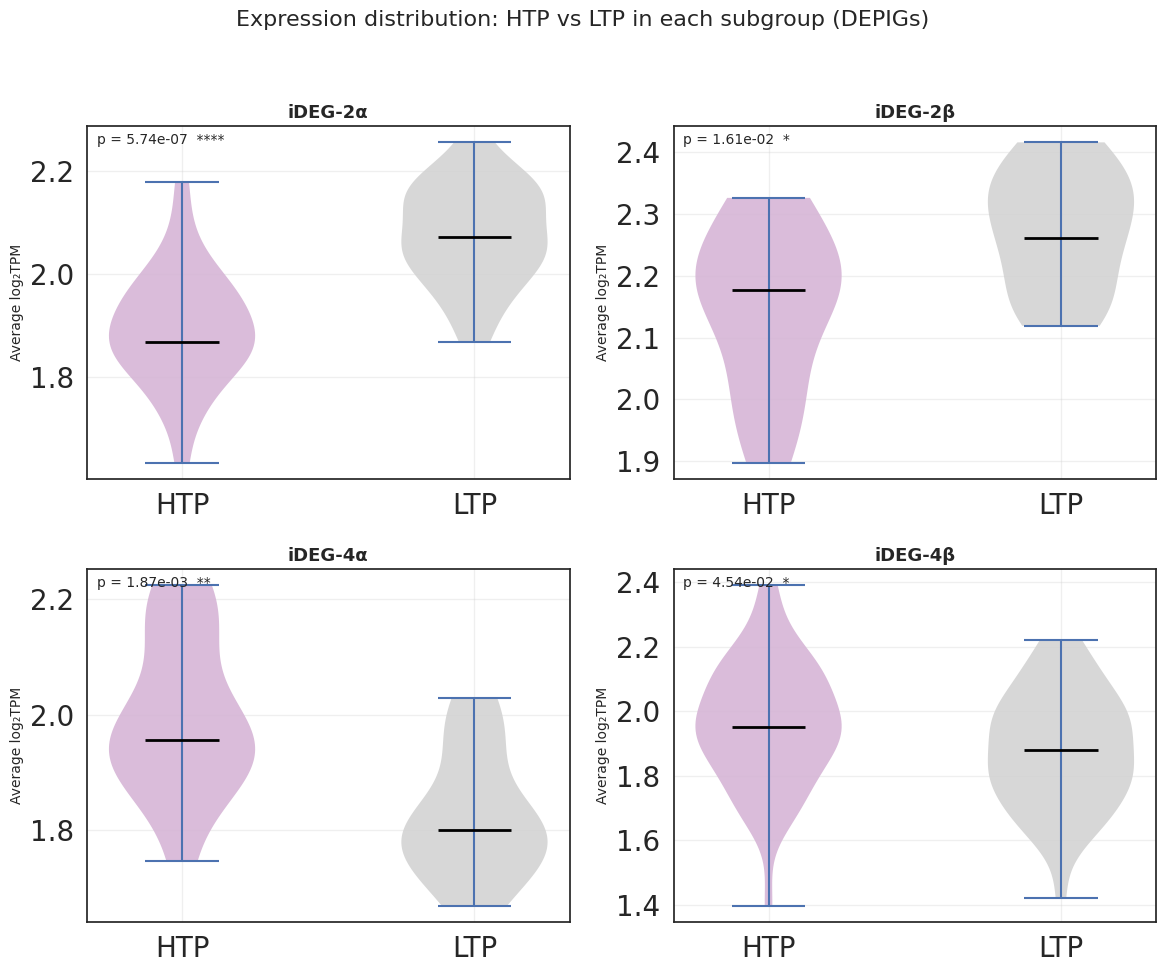

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# =========================
# 1. 辅助函数：读取ID列表
# =========================
def read_ids(filepath):
    with open(filepath, 'r') as f:
        ids = [line.strip() for line in f if line.strip()]
    return ids

# =========================
# 2. 读取细胞亚群（并取并集作为共同细胞，此处保持原过滤逻辑）
# =========================
all_subgroup_files = [
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
]
all_cells = set()
for f in all_subgroup_files:
    all_cells.update(read_ids(f))
common_cells = list(all_cells)

subgroup_2C_H1 = [c for c in read_ids(all_subgroup_files[0]) if c in common_cells]
subgroup_2C_H2 = [c for c in read_ids(all_subgroup_files[1]) if c in common_cells]
subgroup_4C_H1 = [c for c in read_ids(all_subgroup_files[2]) if c in common_cells]
subgroup_4C_H2 = [c for c in read_ids(all_subgroup_files[3]) if c in common_cells]

# =========================
# 3. 读取伪时间（此处不再使用，但保留以防后续需要）
# =========================
time_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t", header=0
)
time_df["pseudotime"] = pd.to_numeric(time_df["pseudotime"])
sample_to_time = dict(zip(time_df["cell_id"], time_df["pseudotime"]))

# =========================
# 4. 读取表达量矩阵并计算 log2TPM
# =========================
expr_all = pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt", sep="\t", index_col=0)
expr_logcpm = np.log2(expr_all + 1)

# =========================
# 5. 定义 HTP 和 LTP 基因集
# =========================
def load_gene_set(filepath):
    genes = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            if len(parts) >= 4:
                genes.append(parts[3])
            else:
                genes.append(parts[0])
    return set(genes)

HTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_0_genes_2cluster_random99.bed")
LTP_genes = load_gene_set("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_cluster_1_genes_2cluster_random99.bed")
print(f"HTP genes total: {len(HTP_genes)}, LTP genes total: {len(LTP_genes)}")

# 读取 expressed_genes 过滤集
expressed_genes_file = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/IVF_morula_boundaries_80k_2C_4C_deboundary2gene_id.txt"
expressed_genes = load_gene_set(expressed_genes_file)
print(f"Expressed genes (filter set): {len(expressed_genes)}")

# =========================
# 6. 构建 z_df（每个细胞 c0 和 c1 的平均表达）
# =========================
HTP_genes_valid = [g for g in HTP_genes if g in expr_logcpm.index and g in expressed_genes]
LTP_genes_valid = [g for g in LTP_genes if g in expr_logcpm.index and g in expressed_genes]
print(f"HTP valid genes: {len(HTP_genes_valid)}, LTP valid genes: {len(LTP_genes_valid)}")

expr_HTP = expr_logcpm.loc[HTP_genes_valid] if HTP_genes_valid else pd.DataFrame()
expr_LTP = expr_logcpm.loc[LTP_genes_valid] if LTP_genes_valid else pd.DataFrame()

if expr_HTP.empty or expr_LTP.empty:
    print("❌ 错误：HTP 或 LTP 有效基因数为 0，请检查基因名匹配或 expressed_genes 文件内容。")
    raise SystemExit

avg_HTP = expr_HTP.mean(axis=0)
avg_LTP = expr_LTP.mean(axis=0)

records = []
for cell in avg_HTP.index:
    records.append({'cell': cell, 'type': 'c0', 'z_score': avg_HTP[cell]})
for cell in avg_LTP.index:
    records.append({'cell': cell, 'type': 'c1', 'z_score': avg_LTP[cell]})
z_df = pd.DataFrame(records)
print(f"z_df 形状: {z_df.shape}")

# =========================
# 7. 定义亚群字典（沿用原名称）
# =========================
subgroups = {
    '2C-iDEG1': subgroup_2C_H1,
    '2C-iDEG2': subgroup_2C_H2,
    '4C-iDEG1': subgroup_4C_H1,
    '4C-iDEG2': subgroup_4C_H2
}

# =========================
# 8. 提取每个亚群内 HTP/LTP 的 z_score 并做统计检验
# =========================
def get_p_annotation(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

subgroup_order = ['2C-iDEG1', '2C-iDEG2', '4C-iDEG1', '4C-iDEG2']
data = {}
p_values = {}

for sg in subgroup_order:
    cells = set(subgroups[sg])
    sub_df = z_df[z_df['cell'].isin(cells)]
    htp_vals = sub_df[sub_df['type'] == 'c0']['z_score'].values
    ltp_vals = sub_df[sub_df['type'] == 'c1']['z_score'].values
    data[sg] = {'HTP': htp_vals, 'LTP': ltp_vals}

    if len(htp_vals) > 0 and len(ltp_vals) > 0:
        p = mannwhitneyu(htp_vals, ltp_vals, alternative='two-sided').pvalue
    else:
        p = np.nan
    p_values[sg] = p

print("\n=== Statistical Tests (Mann-Whitney U) ===")
for sg, p in p_values.items():
    if not np.isnan(p):
        print(f"{sg}: HTP vs LTP  p = {p:.2e}  {get_p_annotation(p)}")
    else:
        print(f"{sg}: NA")

# =========================
# 9. 绘制小提琴图
# =========================
# HTP / LTP 配色（与其他图保持一致）
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}

# 亚群显示名映射（内部键保持不变）
subgroup_display = {
    '2C-iDEG1': 'iDEG-2α',
    '2C-iDEG2': 'iDEG-2β',
    '4C-iDEG1': 'iDEG-4α',
    '4C-iDEG2': 'iDEG-4β',
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, sg in enumerate(subgroup_order):
    ax = axes[idx]
    vals = data[sg]

    parts = ax.violinplot(
        [vals['HTP'], vals['LTP']],
        positions=[1, 2],
        showmeans=False,
        showmedians=True
    )

    # 按 HTP / LTP 分别着色
    for i, pc in enumerate(parts['bodies']):
        label = ['HTP', 'LTP'][i]
        pc.set_facecolor(label_colors[label])
        pc.set_alpha(0.9)
        pc.set_edgecolor('none')

    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(['HTP', 'LTP'])

    # 子图标题（使用新显示名）
    ax.set_title(subgroup_display[sg], fontsize=13, fontweight='bold')
    ax.set_ylabel("Average log₂TPM", fontsize=10)

    p = p_values[sg]
    if not np.isnan(p):
        p_text = f"p = {p:.2e}  {get_p_annotation(p)}"
    else:
        p_text = "p = NA"
    ax.text(0.02, 0.98, p_text, transform=ax.transAxes, va='top', ha='left', fontsize=10)

    ax.grid(alpha=0.3)

plt.suptitle("Expression distribution: HTP vs LTP in each subgroup (DEPIGs)",
             fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Violin_expression_HTP_LTP_subgroups_DEPIGs.svg", dpi=300, bbox_inches='tight')
plt.show()